# Prot2GO: Leveraging Hierarchical Graph Neural Networks for Enhanced Protein Function Annotation
Author: Cleverson M., PhD

## Setting the Environment

### Importing Modules

In [1]:
# Importing modules
import os
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import warnings
import pickle
import requests
from concurrent.futures import ThreadPoolExecutor
import string
import re

import matplotlib.pyplot as plt
import seaborn as sns

from Bio import SeqIO
from obonet import read_obo
import networkx as nx

import spacy
from spacy.lang.en.stop_words import STOP_WORDS

import torch
import torch.nn.functional as F
from torch.nn import Dropout
from torch.utils.data import Dataset, DataLoader

from torch_geometric.utils import structured_negative_sampling_feasible
from torch_geometric.data import Data, HeteroData
from torch_geometric.nn import SAGEConv, GATConv, Linear

from transformers import BertTokenizer, BertModel
from sentence_transformers import SentenceTransformer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    classification_report,
)

# Disable warnings
warnings.filterwarnings("ignore")

# Set CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.environ["TORCH"] = torch.__version__

# Check PyTorch and CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version: {torch.version.cuda}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {device}")

PyTorch version: 2.3.0
CUDA version: 12.1
CUDA available: True
Device: cuda


### Creating Prot2GO Folders

In [3]:
# root path
root = Path("/home/clever/datascience/projects/prot2go")

# List of species
species = ["human", "yeast", "ecoli", "mouse", "elegans", "fruitfly", "benchmark"]

# Base directories
base_directories = [
    "eda",  # EDA of protein and PPI data
    "metadata",  # protein and PPI metadata
    "datasets",  # protein embeddings and PPI torch datasets
    "models",  # saved models and evaluation metrics
]

# Create the directory structure
for specie in species:
    for base_dir in base_directories:
        folder_path = root / specie / base_dir
        folder_path.mkdir(parents=True, exist_ok=True)

# Create directory to save GO
go_folder = root / "go"
go_folder.mkdir(parents=True, exist_ok=True)

# Paths to species' folders
human_folder = root / "human"
ecoli_folder = root / "ecoli"
yeast_folder = root / "yeast"
mouse_folder = root / "mouse"
elegans_folder = root / "elegans"
fruitfly_folder = root / "fruitfly"
benchmark_folder = root / "benchmark"

# define species to train and predict
species_folder = yeast_folder
print(species_folder)

/home/clever/datascience/projects/prot2go/yeast


In [4]:
class NormalizedGATConv(GATConv):
    def forward(self, x, edge_index):
        x, alpha = super().forward(x, edge_index, return_attention_weights=True)
        alpha = alpha / alpha.sum(dim=1, keepdim=True)  # Normalize the attention coefficients
        return x * alpha

class HGNNGATWithNormalizedAttention(torch.nn.Module):
    def __init__(self, protein_features, go_features, out_features, dropout=0.6, heads=8, concat=True):
        super(HGNNGATWithNormalizedAttention, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = NormalizedGATConv(protein_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv1_go = NormalizedGATConv(go_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_protein = NormalizedGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_go = NormalizedGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        final_out_features = out_features if concat else per_head_features
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        x_protein = F.elu(self.conv1_protein(x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")]))
        x_protein = F.elu(self.conv2_protein(x_protein, edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))
        
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores


### Custom Functions

#### Text Preprocessing and Tokenization (spacy)

In [5]:
nlp = spacy.load("en_core_web_sm")  # Load spaCy model

# Custom punctuation removal (preserving "-" and "/" for gene names)
custom_punctuation = string.punctuation.replace("-", "").replace("/", "")


def text_preprocessing_spacy(text=str):
    """
    Preprocesses the input text using spaCy.

    This function tokenizes the input text, removes custom punctuation,
    converts tokens to lowercase, removes stop words, and lemmatizes the tokens.

    Args:
        text (str): The input text to preprocess.

    Returns:
        str: The preprocessed and lemmatized text as a single string.
    """
    doc = nlp(text)
    tokens = [token.text for token in doc]
    tokens = [token for token in tokens if token not in custom_punctuation]
    tokens = [token.lower for token in tokens]
    tokens = [token for token in tokens if token not in STOP_WORDS]
    lemmas = [token.lemma_ for token in doc]
    return " ".join(lemmas)


def process_node(item):
    """
    Extracts and preprocesses Gene Ontology (GO) Directed Acyclic Graph (DAG) node data.

    This function processes a given GO term and its attributes, extracts the definition,
    preprocesses the definition text using spaCy, and returns relevant information about the GO term.

    Args:
        item (tuple): A tuple containing the GO term (str) and its attributes (dict).

    Returns:
        dict: A dictionary containing the GO term ID, name, namespace, original definition,
              definition word count, preprocessed definition, and preprocessed word count.
    """
    go_term, attr = item
    definition = attr["def"].split('"', 2)[1]
    preprocessed_text = text_preprocessing_spacy(definition)
    return {
        "go_id": go_term,
        "name": attr["name"],
        "aspect": attr["namespace"],
        "def": definition,
        "def_word_count": len(re.findall(r"\w+", definition)),
        "preprocessed": preprocessed_text,
        "preproc_word_count": len(preprocessed_text.split()),
    }

#### Visualization of GO Aspect Ratios (BP, MF, CC) in Datasets

In [6]:
def plot_ratio(df: pd.DataFrame) -> None:
    """
    Plots the aspect ratio of GO terms from a given DataFrame.

    Parameters:
    df (pd.DataFrame): A DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays a horizontal bar plot of the GO term aspects in percentage.
    """
    # Aspect ratio (BP, MF, CC) in percentage
    aspect_ratio = df["aspect"].value_counts(normalize=True) * 100

    plt.figure(figsize=(10, 6))

    # Horizontal bar plot for GO aspects
    go_aspect = sns.barplot(
        y=aspect_ratio.index, x=aspect_ratio.values, palette="pastel"
    )
    go_aspect.set_title("GO aspects (BP, MF, CC) Distribution")
    go_aspect.set_xlabel("Percentage", fontsize=14)
    go_aspect.set_ylabel("GO Aspects", fontsize=14)
    go_aspect.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio.values):
        plt.text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()


def plot_ratio_compare(df1: pd.DataFrame, df2: pd.DataFrame) -> None:
    """
    Compares the aspect ratios of GO terms between two datasets.

    Parameters:
    df1 (pd.DataFrame): The first DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.
    df2 (pd.DataFrame): The second DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays horizontal bar plots of the GO term aspects in percentage for both datasets.
    """
    # Aspect ratios (BP, MF, CC) in percentage for both datasets
    aspect_ratio1 = df1["aspect"].value_counts(normalize=True) * 100
    aspect_ratio2 = df2["aspect"].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(20, 6))

    # Horizontal bar plot for GO aspects in the first dataset
    go_aspect1 = sns.barplot(
        ax=ax[0], y=aspect_ratio1.index, x=aspect_ratio1.values, palette="pastel"
    )
    go_aspect1.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 1)")
    go_aspect1.set_xlabel("Percentage", fontsize=14)
    go_aspect1.set_ylabel("GO Aspects", fontsize=14)
    go_aspect1.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio1.values):
        ax[0].text(value, index, f"{value:.2f}%", va="center")

    # Horizontal bar plot for GO aspects in the second dataset
    go_aspect2 = sns.barplot(
        ax=ax[1], y=aspect_ratio2.index, x=aspect_ratio2.values, palette="pastel"
    )
    go_aspect2.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 2)")
    go_aspect2.set_xlabel("Percentage", fontsize=14)
    go_aspect2.set_ylabel("GO Aspects", fontsize=14)
    go_aspect2.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio2.values):
        ax[1].text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()

#### TF-IDF of GO Definitions

In [7]:
def plot_tfidf(
    texts,
    max_df=0.85,
    min_df=2,
    n_gram_range=(1, 2),
    top_n=25,
):
    """
    Computes and visualizes the top N terms with the highest TF-IDF scores.

    Parameters:
    - texts (iterable): Iterable (list, np.array, pd.Series) containing the text data.
    - max_df (float): Maximum document frequency allowed for tokens. This is used to ignore terms that appear too frequently and are not informative.
    - min_df (int or float): Minimum document occurrence required for tokens. If an integer, specifies the number of documents a term must appear in to be considered; if a float, specifies the fraction of documents.
    - n_gram_range (tuple): The lower and upper boundary of the range of n-values for different n-grams to be extracted.
    - top_n (int): Number of top terms to visualize.

    Returns:
    - None: Displays a bar chart of the top terms with their TF-IDF scores.
    """
    # Ensure input is in an appropriate format for vectorization
    if isinstance(texts, pd.Series):
        texts = texts.values  # Convert pd.Series to np.array
    elif isinstance(texts, list):
        texts = np.array(texts)  # Convert list to np.array

    # Initialize the TfidfVectorizer
    vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=n_gram_range)

    # Generate the TF-IDF matrix
    tf_idf_matrix = vectorizer.fit_transform(texts)
    features = vectorizer.get_feature_names_out()

    # Compute the maximum TF-IDF score for each feature across all documents
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()

    # Obtain sorted indices (descending order) and select the top N features
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = features[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    # Create a bar chart
    plt.figure(figsize=(12, 8))
    bars = plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores")
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score on top

    # Add data labels to each bar
    for bar in bars:
        plt.gca().text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}",
            ha="left",
            va="center",
            color="black",
        )

    # Show plot with interactive mode on
    plt.grid(False)
    plt.show()

#### PPI Data Preprocessing (DIP database)

In [8]:
def extract_uniprot_ids(field):
    """
    Extracts the UniProt ID from a given field.

    Parameters:
    field (str): A string containing UniProt IDs in the format "uniprotkb:ID".

    Returns:
    str or None: The extracted UniProt ID or None if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    for uniprot_id in split_field:
        if uniprot_id.startswith("uniprotkb"):
            return uniprot_id.split(":")[1]
    return None


def extract_methods(field):
    """
    Extracts methods enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing methods in the format "method (detail)".

    Returns:
    str: Semi-colon separated methods or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        re.search(r"\((.*?)\)", method).group(1)
        for method in split_field
        if re.search(r"\((.*?)\)", method)
    ]
    return ";".join(fragment_list) if fragment_list else ""


def extract_taxiIDs(field):
    """
    Extracts the first numeric ID from a given field.

    Parameters:
    field (str): A string containing numeric IDs.

    Returns:
    str or None: The extracted ID or None if not found.
    """
    if pd.isna(field):
        return None
    pattern = re.compile(r"\b\d+\b")
    match = pattern.search(field)
    return match.group(0) if match else None


def extract_ppi_type(field):
    """
    Extracts unique PPI types enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing PPI types in the format "type (detail)".

    Returns:
    str: Semi-colon separated unique PPI types or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_set = {
        re.search(r"\((.*?)\)", ppi_type).group(1)
        for ppi_type in split_field
        if re.search(r"\((.*?)\)", ppi_type)
    }
    return ";".join(fragment_set) if fragment_set else ""


def extract_confidence_score(field):
    """
    Extracts the confidence score from a given field.

    Parameters:
    field (str): A string containing confidence score in the format "label:score".

    Returns:
    str or None: The extracted confidence score or None if not found.
    """
    if pd.isna(field):
        return None
    parts = field.split(":")
    return parts[1] if len(parts) > 1 else None

#### Generate Negative Edges of protein-GO associations

In [9]:
def generate_negative_edges(
    edge_index,
    num_nodes_protein,
    num_nodes_go,
    num_neg_samples,
    protein_mapping,
    go_mapping,
    weighted=False,
    random_state=42,
    max_attempts_factor=10,
):
    """
    Generate negative samples for a graph, ensuring minimal false negatives and balanced degree distribution if weighted.
    Map the negative samples back to UniProt IDs and GO terms.

    Parameters:
    edge_index (torch.Tensor): Edge index tensor of shape [2, num_edges].
    num_nodes_protein (int): Number of protein nodes.
    num_nodes_go (int): Number of GO nodes.
    num_neg_samples (int): Desired number of negative samples.
    protein_mapping (dict): Dictionary containing protein IDs mapped to continuous integer indices.
    go_mapping (dict): Dictionary containing GO term IDs mapped to continuous integer indices.
    weighted (bool): Whether to use the weighted approach for generating negative samples.
    random_state (int): Seed for random number generator.
    max_attempts_factor (int): Factor to determine the maximum number of attempts to find valid negative samples.

    Returns:
    tuple: A tuple containing the tensor of negative samples and a DataFrame containing the negative samples mapped to UniProt IDs and GO terms.
    """
    rng = np.random.default_rng(random_state)

    # Create a set of existing edges for quick lookup
    existing_edges = set(map(tuple, edge_index.t().tolist()))

    if weighted:
        # Calculate the degree (number of true GO terms) for each protein node
        protein_degrees = np.zeros(num_nodes_protein, dtype=int)
        for protein_node, go_node in edge_index.t().tolist():
            protein_degrees[protein_node] += 1

    # Initialize variables
    negative_samples = []
    attempts = 0
    max_attempts = num_neg_samples * max_attempts_factor
    neg_degree_count = np.zeros(num_nodes_protein, dtype=int) if weighted else None

    while len(negative_samples) < num_neg_samples and attempts < max_attempts:
        if weighted:
            # Select protein nodes based on their degree
            protein_node = rng.choice(
                num_nodes_protein, p=protein_degrees / protein_degrees.sum()
            )
        else:
            # Select protein nodes uniformly
            protein_node = rng.integers(0, num_nodes_protein)

        go_node = rng.integers(0, num_nodes_go)

        # Check if this is a valid negative sample
        if (protein_node, go_node) not in existing_edges:
            negative_samples.append([protein_node, go_node])
            if weighted:
                neg_degree_count[protein_node] += 1

        attempts += 1

    # Convert the list of negative samples to a torch tensor
    if negative_samples:
        neg_sample_tensor = torch.tensor(negative_samples, dtype=torch.long).t()
    else:
        neg_sample_tensor = torch.empty(
            (2, 0), dtype=torch.long
        )  # Return an empty tensor with the correct shape

    # Swap key-value for mapping
    protein_mapping = {v: k for k, v in protein_mapping.items()}
    go_mapping = {v: k for k, v in go_mapping.items()}

    # Map the negative samples back to UniProt IDs and GO terms
    mapped_negative_samples = [
        {
            "uniprot_id": protein_mapping.get(u_idx, None),
            "go_id": go_mapping.get(g_idx, None),
            "uniprot_idx": u_idx,
            "go_idx": g_idx,
        }
        for u_idx, g_idx in negative_samples
    ]

    mapped_negative_samples_df = pd.DataFrame(mapped_negative_samples)

    return neg_sample_tensor, mapped_negative_samples_df

#### Visualize Positive and Negative Edges Distributions

In [10]:
def check_balance(
    positive_edge_index, negative_edge_index, num_nodes_protein, num_nodes_go
):
    """
    Check the balance of negative samples compared to positive samples.

    Parameters:
    positive_edge_index (torch.Tensor): Positive edge index tensor of shape [2, num_edges].
    negative_edge_index (torch.Tensor): Negative edge index tensor of shape [2, num_neg_samples].
    num_nodes_protein (int): Number of protein nodes.
    num_nodes_go (int): Number of GO nodes.

    Returns:
    None: Displays histograms comparing the degree distributions.
    """
    # Calculate the degree of each protein and GO node in positive samples
    protein_degrees_pos = np.zeros(num_nodes_protein, dtype=int)
    go_degrees_pos = np.zeros(num_nodes_go, dtype=int)
    for protein_node, go_node in positive_edge_index.t().tolist():
        protein_degrees_pos[protein_node] += 1
        go_degrees_pos[go_node] += 1

    # Calculate the degree of each protein and GO node in negative samples
    protein_degrees_neg = np.zeros(num_nodes_protein, dtype=int)
    go_degrees_neg = np.zeros(num_nodes_go, dtype=int)
    for protein_node, go_node in negative_edge_index.t().tolist():
        protein_degrees_neg[protein_node] += 1
        go_degrees_neg[go_node] += 1

    # Plot histograms of the degree distributions
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.kdeplot(
        protein_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
    )
    sns.kdeplot(
        protein_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5
    )
    plt.title("Protein Degree Distribution")
    plt.xlabel("Degree")
    plt.ylabel("Density")
    plt.legend()

    plt.subplot(1, 2, 2)
    sns.kdeplot(go_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5)
    sns.kdeplot(go_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5)
    plt.title("GO Terms Degree Distribution")
    plt.xlabel("Degree")
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()

#### Training and Validation Metrics

In [11]:
def plot_loss_and_accuracy(metrics, species_folder, discard_first_epochs=5):
    """
    Plots training and validation loss and accuracy over epochs.

    Parameters:
    metrics (dict): Dictionary containing training and validation metrics.
    dst_folder: species folder
    discard_first_epochs (int): Number of initial epochs to discard from the plot.
    """

    # Ensure dst_folder Path object
    species_folder = Path(species_folder) / "models"

    epochs = list(metrics["train_losses"].keys())[discard_first_epochs - 1 :]
    train_losses = list(metrics["train_losses"].values())[discard_first_epochs - 1 :]
    train_aurocs = list(metrics["train_aurocs"].values())[discard_first_epochs - 1 :]

    val_losses = list(metrics["val_losses"].values())[discard_first_epochs - 1 :]
    val_aurocs = list(metrics["val_aurocs"].values())[discard_first_epochs - 1 :]

    # Plot Loss
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label="Train Loss")
    plt.plot(epochs, val_losses, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.title("Loss over Epochs")

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_aurocs, label="Train AUROC")
    plt.plot(epochs, val_aurocs, label="Validation AUROC")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.title("AUROC over Epochs")
    plt.savefig(species_folder / "training_metrics.png", dpi=300)
    plt.show()


def plot_ratio_compare(df1: pd.DataFrame, df2: pd.DataFrame) -> None:
    """
    Compares the aspect ratios of GO terms between two datasets.

    Parameters:
    df1 (pd.DataFrame): The first DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.
    df2 (pd.DataFrame): The second DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays horizontal bar plots of the GO term aspects in percentage for both datasets.
    """
    # Aspect ratios (BP, MF, CC) in percentage for both datasets
    aspect_ratio1 = df1["aspect"].value_counts(normalize=True) * 100
    aspect_ratio2 = df2["aspect"].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(20, 6))

    # Horizontal bar plot for GO aspects in the first dataset
    go_aspect1 = sns.barplot(
        ax=ax[0], y=aspect_ratio1.index, x=aspect_ratio1.values, palette="pastel"
    )
    go_aspect1.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 1)")
    go_aspect1.set_xlabel("Percentage", fontsize=14)
    go_aspect1.set_ylabel("GO Aspects", fontsize=14)
    go_aspect1.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio1.values):
        ax[0].text(value, index, f"{value:.2f}%", va="center")

    # Horizontal bar plot for GO aspects in the second dataset
    go_aspect2 = sns.barplot(
        ax=ax[1], y=aspect_ratio2.index, x=aspect_ratio2.values, palette="pastel"
    )
    go_aspect2.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 2)")
    go_aspect2.set_xlabel("Percentage", fontsize=14)
    go_aspect2.set_ylabel("GO Aspects", fontsize=14)
    go_aspect2.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio2.values):
        ax[1].text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()

#### Evaluation of Model Performance

In [12]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask):
    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        val_loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask].cpu())
        predictions = out.sigmoid()
        val_auroc = roc_auc_score(
            edge_labels[val_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )
    return val_loss.item(), val_auroc


def predict(model, x_dict, edge_index_dict, edge_labels, test_mask):
    model.eval()  # Set evaluation mode
    with torch.no_grad():
        # Forward pass using the test mask
        out = model(x_dict, edge_index_dict, test_mask)
        probabilities = out.sigmoid()  # Convert logits to probabilities

        # Ensure tensor operations are on the same device
        test_labels = edge_labels[test_mask].to(probabilities.device)

        # Calculate the AUROC
        auroc = roc_auc_score(
            test_labels.cpu().detach().numpy(), probabilities.cpu().detach().numpy()
        )

        # Calculate accuracy
        predicted_classes = (
            probabilities > 0.5
        ).float()  # Threshold probabilities to binary
        val_auroc = roc_auc_score(
            test_labels.cpu().detach().numpy(), predicted_classes.cpu().detach().numpy()
        )

        return predicted_classes, test_labels, auroc, val_auroc, probabilities

In [13]:
def evaluate_model_performance(
    model,
    hetero_data,
    associations_df,
    go_id_map,
    save_path,
):

    # Ensure Path object of save path
    save_path = Path(save_path) / "models"

    # Extract test mask
    test_mask = hetero_data["protein", "associates_with", "go"].test_mask

    # Predict
    predicted_labels, test_labels, test_auroc, test_bal_accuracy, probabilities = (
        predict(
            model,
            hetero_data.x_dict,
            hetero_data.edge_index_dict,
            hetero_data["protein", "associates_with", "go"].edge_label,
            test_mask,
        )
    )

    # Retrieve the indices of the test edges
    test_edge_indices = hetero_data["protein", "associates_with", "go"].edge_index[
        :, test_mask
    ]

    # Get the protein and GO indices
    protein_indices = test_edge_indices[0].cpu().numpy()
    go_indices = test_edge_indices[1].cpu().numpy()

    # Map indices to IDs
    protein_id_map = dict(
        zip(
            associations_df["uniprot_idx"].astype(int),
            associations_df["uniprot_id"],
        )
    )
    go_id_map = {v: k for k, v in go_id_map.items()}  # swap mapping

    # Prepare data for the DataFrame
    data = {
        "Protein ID": [protein_id_map.get(idx, "Unknown") for idx in protein_indices],
        "GO ID": [go_id_map.get(idx, "Unknown") for idx in go_indices],
        "Ground Truth Label": [label.item() for label in test_labels],
        "Predicted Label": [label.item() for label in predicted_labels],
        "Probability": [prob.item() for prob in probabilities],
    }

    # Create and save df
    results_df = pd.DataFrame(data)
    results_df.to_csv(save_path / "test_results.csv", index=False)

    # Plot metrics
    print(f"AUROC test: {test_auroc}")
    print(f"Balanced accuracy test: {test_bal_accuracy}")

    # Save classification report and print
    class_report = classification_report(
        test_labels, predicted_labels, target_names=["0", "1"]
    )

    with open(save_path / "classification_report.txt", "w") as file:
        file.write(class_report)

    print(class_report)

    disp = ConfusionMatrixDisplay.from_predictions(
        test_labels,
        predicted_labels,
        normalize="true",
        cmap="Blues",
        values_format=".1%",
    )
    plt.savefig(save_path / "confusion_matrix.png", dpi=300)
    plt.show()

    return results_df

#### Map Dictionary Values to Keys

In [14]:
def map_dict_values(dict_to_map, dict_value):
    keys = list(dict_to_map.keys())
    values = list(dict_to_map.values())
    position = values.index(dict_value)
    return keys[position]

### Custom Classes

#### ProteinDataset Class

The `ProteinDataset` class is designed for reading and preprocessing protein sequences to generate embeddings. It leverages a DataFrame containing UniProt IDs, protein sequences (in 1-letter amino acid code), and their sequence lengths. This class ensures that each sequence is appropriately preprocessed before being fed into a model.

In [15]:
class ProteinDataset(Dataset):
    """
    A PyTorch Dataset class for reading and preprocessing protein sequences for embedding generation.

    Attributes:
        dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").

    Methods:
        __len__: Returns the number of files in the dataset.
        __getitem__: Retrieves a sequence and its identifier by index, applying preprocessing.
    """

    def __init__(self, dataframe):
        """
        Initializes the ProteinDataset with a dataframe.

        Parameters:
            dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").
        """
        self.dataframe = dataframe

    def __len__(self):
        """
        Provides the size of the dataset.

        Returns:
            int: The number of sequences in the dataframe.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieves the sequence and its identifier at the specified index after preprocessing.

        Parameters:
            idx (int): The index of the sequence to retrieve.

        Returns:
            tuple: A tuple containing the preprocessed sequence and its id.
        """
        row = self.dataframe.iloc[idx]
        seq = " ".join(row["sequence"].replace(r"[UZOB]", "X"))

        return seq, row["uniprot_id"]

#### ProteinEmbeddingDataset Class

The `ProteinEmbeddingDataset` class is designed to load protein embeddings stored as **.pt (PyTorch tensor)** files. Each tensor file contains the embedding of a protein, identified by a UniProt ID. This class optimizes memory usage by loading each embedding as needed, making it suitable for handling large datasets.

In [16]:
class ProteinEmbeddingDataset(Dataset):
    """
    A PyTorch Dataset for loading protein embeddings stored as .pt (PyTorch tensor) files.

    Each tensor file contains the embedding of a protein, identified by a UniProt ID. This dataset
    facilitates the access to these embeddings for model training or inference, ensuring each
    embedding is loaded as needed, thus optimizing memory usage.

    Attributes:
        tensor_folder (str): The directory path where the embedding tensors (.pt files) are stored.
        uniprot_ids (list): A list of UniProt IDs corresponding to the proteins for which embeddings are available.

    Methods:
        __len__: Returns the total number of embeddings available in the dataset.
        __getitem__: Retrieves an embedding by its index, along with its corresponding UniProt ID.

    Parameters:
        tensor_folder (str): Path to the folder where tensor files, representing protein embeddings, are stored.
                             Each file should be named with the UniProt ID of the protein it represents.
    """

    def __init__(self, tensor_folder):
        """
        Initializes the dataset with the path to the directory containing the embeddings.

        Args:
            tensor_folder (string): Path to the folder where tensors are stored.
        """
        self.tensor_folder = tensor_folder
        self.uniprot_ids = [
            file.split(".")[0]
            for file in os.listdir(tensor_folder)
            if file.endswith(".pt")
        ]

    def __len__(self):
        """
        Returns the total number of protein embeddings available.

        Returns:
            int: The count of UniProt ID-based tensor files in the tensor folder.
        """
        return len(self.uniprot_ids)

    def __getitem__(self, idx):
        """
        Retrieves a specific protein embedding and its corresponding UniProt ID by index.

        This method ensures that the embedding tensor is loaded from disk only when accessed,
        optimizing memory usage, especially useful when dealing with large datasets.

        Args:
            idx (int): The index of the protein embedding to retrieve.

        Returns:
            dict: A dictionary containing the UniProt ID ('uniprot_id') and the embedding tensor ('tensor').
                  The tensor is expected to have a shape of (1, 1024).

        Raises:
            AssertionError: If the loaded tensor does not match the expected shape of (1, 1024).
        """
        uniprot_id = self.uniprot_ids[idx]
        tensor_path = os.path.join(self.tensor_folder, uniprot_id + ".pt")
        tensor = torch.load(tensor_path)

        # Asserting the tensor is in the correct shape ensures consistency and prevents potential errors in downstream processes.
        assert tensor.shape == (
            1,
            1024,
        ), f"Tensor shape mismatch: {tensor.shape} != (1, 1024)"

        return {"uniprot_id": uniprot_id, "tensor": tensor}

#### Protein Sequence Embedding with ProtTrans

The `embed_sequences` function processes protein sequences from a DataFrame, generating embeddings using a pre-trained BERT model. This function can save embeddings at either the protein level or the residue level, based on the specified parameters.

In [17]:
def embed_sequences(
    dataframe: pd.DataFrame, out_dir: Path, per_residue=False, batch_size=1
):
    """
    Processes protein sequences from a folder, generating embeddings using a pre-trained BERT model.

    Parameters:
        dataframe (pd.DataFrame): A dataframe with protein IDs, corresponding peptide sequences and their lengths.
        per_residue (bool): If True, saves per-residue embeddings; otherwise, saves per-protein embeddings.
        batch_size (int): The batch size for processing sequences.
    """

    print(f"Loading transformer and tokenizer...")
    tokenizer = BertTokenizer.from_pretrained("Rostlab/prot_bert", do_lower_case=False)
    model = BertModel.from_pretrained("Rostlab/prot_bert")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).half().eval()  # move model to gpu and set half-precision (float16)

    # Creates directories to save embeddings
    out_dir = Path(out_dir)  # ensures Path object
    out_dir.mkdir(parents=True, exist_ok=True)

    per_protein_path = out_dir / "per_protein"
    per_protein_path.mkdir(exist_ok=True, parents=True)

    per_residue_path = out_dir / "per_residue" if per_residue else None
    if per_residue_path:
        per_residue_path.mkdir(exist_ok=True, parents=True)

    # Reads fasta files in input folder
    dataset = ProteinDataset(dataframe)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for seqs, ids in tqdm(loader, desc="Embedding sequences"):
        for seq, seq_id in zip(seqs, ids):

            # Tokenize and move input tensors to the same device as the model
            inputs = tokenizer(seq, padding=True, truncation=True, return_tensors="pt")
            inputs = {key: tensor.to(device) for key, tensor in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)
            protein_embeddings = outputs.last_hidden_state[
                :, : len(seq.replace(" ", "")) + 1
            ]

            # Detach and move to CPU before saving
            protein_embeddings = protein_embeddings.mean(dim=1).detach().cpu()
            torch.save(protein_embeddings, per_protein_path / f"{seq_id}.pt")

            if per_residue:
                residue_embeddings = outputs.last_hidden_state[
                    :, : len(seq.replace(" ", "")) + 1
                ]
                torch.save(
                    residue_embeddings.detach().cpu(),
                    per_residue_path / f"{seq_id}_res_embed.pt",
                )

    print(f"All proteins embedded successfully.")

#### Text Embedding with Sentence Transformer

This section describes how to embed text data from a DataFrame using a Sentence Transformer model. It includes a custom PyTorch `Dataset` class for handling the text data and a function for generating the embeddings.

The `TextDataset` class is a simple custom dataset designed to work with text data stored in a DataFrame. It facilitates easy integration with PyTorch's DataLoader for batching and iterating over the text data.


In [18]:
class TextDataset(Dataset):
    def __init__(self, dataframe, text_column):
        self.texts = dataframe[text_column].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def embed_texts(df, column_id, column_text):
    """
    Generates embeddings for text data in a DataFrame using a Sentence Transformer model.

    Parameters:
    - df (pandas.DataFrame): The DataFrame containing the text data.
    - column_id (str): The name of the column in the DataFrame that contains the identifiers for the text.
    - column_text (str): The name of the column in the DataFrame that contains the text to be embedded.

    Returns:
    - dict: A dictionary where the keys are entries from `column_id` and the values are the embeddings
            generated from the text in `column_text`.
    """
    # Load Sentence Transformer
    model = SentenceTransformer(
        "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cuda:0"
    )

    # Create dataset from DataFrame
    dataset = TextDataset(df, column_text)
    dataloader = DataLoader(dataset, batch_size=128, shuffle=False)

    embeddings_dict = dict()
    for texts in tqdm(dataloader, total=len(dataloader)):
        embeddings = model.encode(
            texts, show_progress_bar=False, convert_to_tensor=True
        )
        for text, emb in zip(texts, embeddings):
            go_id = df[df[column_text] == text][column_id].values[0]
            embeddings_dict[go_id] = emb.cpu().numpy()

    print("All texts embedded successfully.")
    return embeddings_dict

## Prepare GO Graph Data

### Download and Parse Up-to-Date Gene Ontology (GO) Graph

In [19]:
address = "https://purl.obolibrary.org/obo/go/go-basic.obo"
filepath = "go/go-basic.obo"
response = requests.get(address)
response.raise_for_status()  # Check for download errors

with open(filepath, "wb") as f:
    f.write(response.content)

# Load GO Directed Acyclic Graph (GO-DAG)
go_graph = read_obo(root / "go/go-basic.obo")

print(go_graph)
print(f"Format version: {go_graph.graph['format-version']}")
print(f"Data version: {go_graph.graph['data-version'][-10:]}")
print(f"Is Directed Acyclic Graph?: {nx.is_directed_acyclic_graph(go_graph)}")
print(f"Is strongly connected?: {nx.is_strongly_connected(go_graph)}")

MultiDiGraph named 'go' with 42255 nodes and 81848 edges
Format version: 1.2
Data version: 2024-04-24
Is Directed Acyclic Graph?: True
Is strongly connected?: False


### Extract and Tokenize GO Terms' Definitions

In [ ]:
with ThreadPoolExecutor(
    max_workers=16
) as executor:  # Increase max_workers if you have more CPU cores
    results = list(
        tqdm(
            executor.map(process_node, go_graph.nodes.items()),
            total=len(go_graph.nodes),
            desc="Processing GO graph nodes...",
        )
    )

# Create DataFrame from results
go_df = pd.DataFrame(results)

# Assert if all nodes are in df and save
assert len(go_df) == len(go_graph.nodes), "Mismatch in the number of nodes."
go_df.to_csv(go_folder / "go-basic-tokenized.csv", index=False)

print(f"DataFrame dimensions: {go_df.shape}")
print(go_df.head().to_markdown())

# Plot the distribution of word counts in the 'preprocessed' column
go_df["preproc_word_count"].plot(
    kind="hist", bins=50, edgecolor="black", figsize=(10, 6)
)
plt.title("Distribution of Word Counts in Preprocessed GO Definitions")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.savefig(go_folder / "word_count_hist.png", dpi=300)
plt.show()

# Get descriptive statistics for the word counts
print(go_df["preproc_word_count"].describe())

### Generate Embeddings

In [ ]:
go_embed_dict = embed_texts(go_df, "go_id", "preprocessed")

# Save GO embeddings dict
save_file_path = go_folder / "go_embeddings_dict.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

### Load Embeddings

In [20]:
# Load tokenized dataset and GO embeddings dict

go_df = pd.read_csv(go_folder / "go-basic-tokenized.csv")
print(f"GO df shape: {go_df.shape}")
display(go_df.head())


save_file_path = go_folder / "go_embeddings_dict.pkl"
with open(save_file_path, "rb") as file:
    go_embed_dict = pickle.load(file)

print(f"GO embeddings dict length: {len(go_embed_dict)}")
for key, value in go_embed_dict.items():
    print(f"GO id: {key}, embedding: {value[:10]}")
    break

GO df shape: (42255, 7)


,go_id,name,aspect,def,def_word_count,preprocessed,preproc_word_count
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,"the distribution of mitochondria , include the...",27
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,the maintenance of the structure and integrity...,21
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,enable the transfer of zinc ion ( zn2 + ) from...,51
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,enable the transfer of a solute or solute from...,58
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,catalysis of the transfer of a mannose residue...,18


GO embeddings dict length: 42255
GO id: GO:0000001, embedding: [-0.01411815  0.20184167  0.02462047  0.00350101  0.5851656   0.00643371
 -0.03821412  0.15378235  0.17802016 -0.02932359]


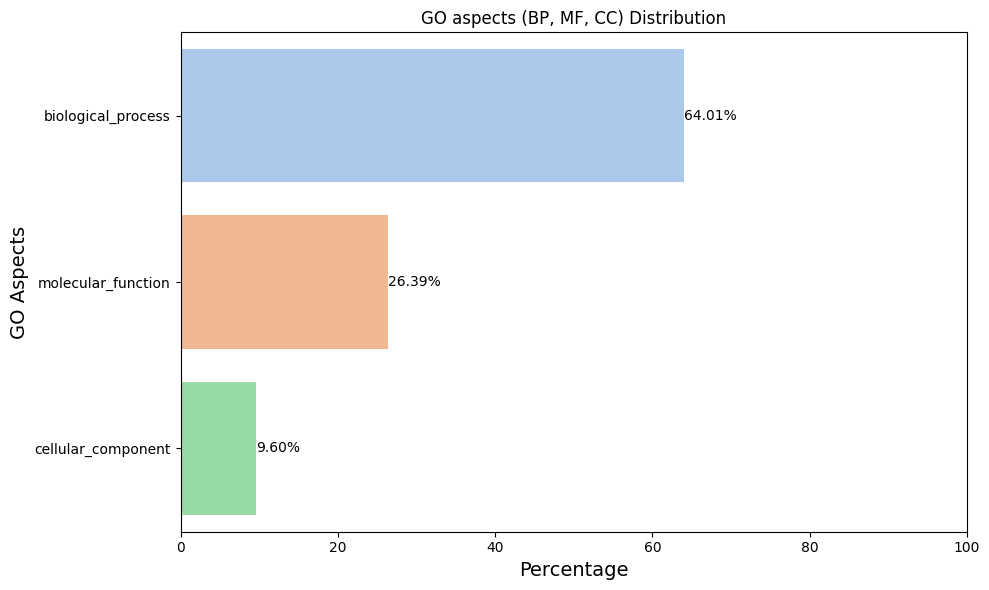

In [21]:
plot_ratio(go_df)

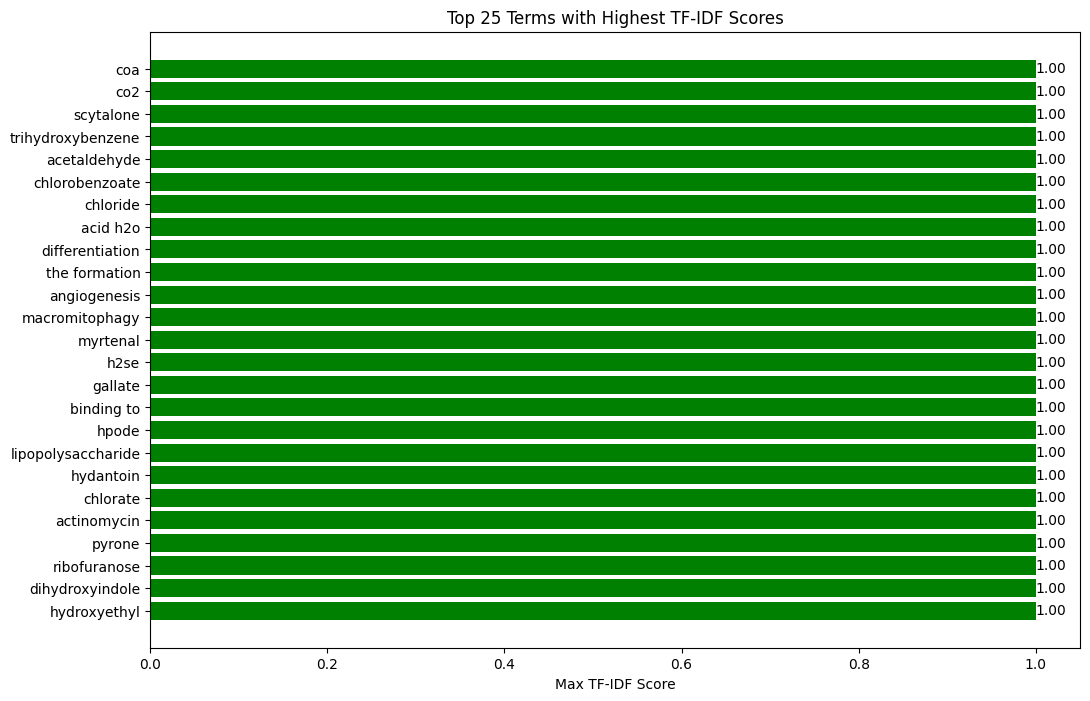

In [22]:
plot_tfidf(go_df["def"], 0.05)

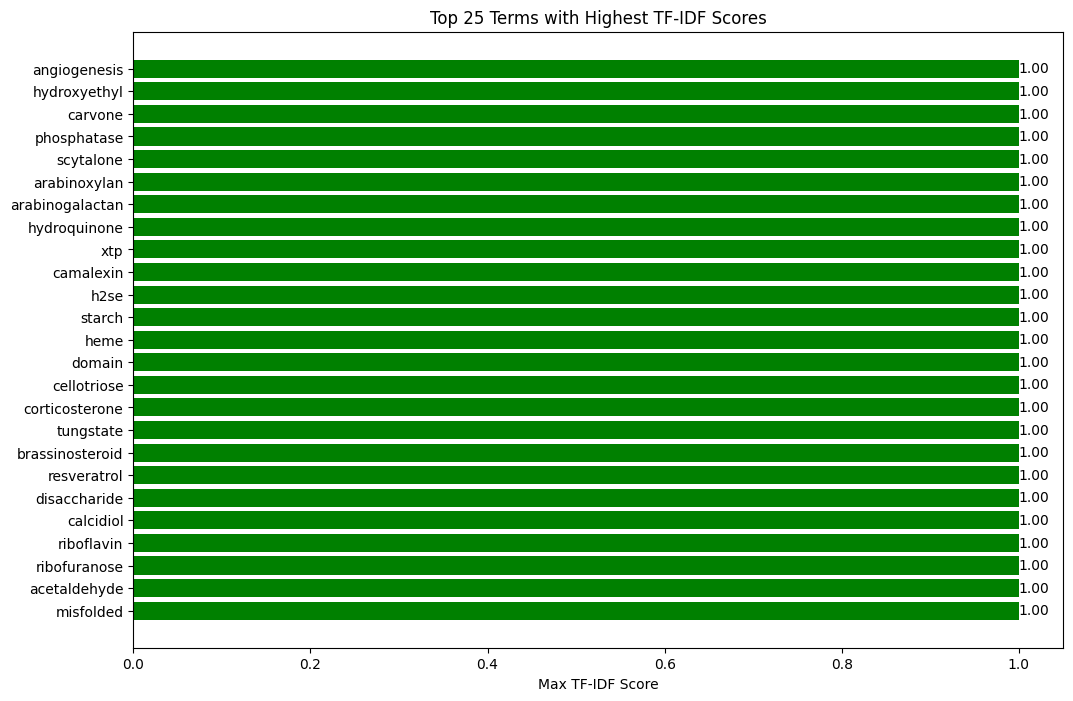

In [23]:
plot_tfidf(go_df["preprocessed"], 0.05)

### Build GO Graph

In [24]:
# Map GO nodes and feature tensors to unique indices

# Convert features to tensors
go_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in go_embed_dict.values()]
)

# Create mapping dict
go_ids = list(go_embed_dict.keys())
go_ids_map = dict(zip(go_ids, range(len(go_ids))))
go_feats_map = dict(zip(go_ids, go_feats))

print(f"# of embeddings: {len(go_embed_dict)}")

print(f"# of unique GO terms: {len(go_ids)}")

for key, value in go_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in go_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of embeddings: 42255
# of unique GO terms: 42255
key: GO:0000001, value: 0
key: GO:0000001, value: torch.Size([384])


#### Multiple Edge Types

#### Single Edge Type

In [25]:
# Create GO graph edge_index (intra-edges)

edges_to_tensor = [
    [go_ids_map[e[0]], go_ids_map[e[1]]] for e in go_graph.edges(data=True)
]
edge_index_go = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_go.shape}")
edge_index_go

edge_index shape: torch.Size([2, 81848])


tensor([[    0,     0,     1,  ..., 42254, 42254, 42254],
        [22429, 22431,  4625,  ..., 33801, 36334, 42253]])

In [26]:
# Creates torch geometric HeteroData object and save GO graph

go_data = Data()
go_data.x = go_feats
go_data.edge_index = edge_index_go

# Save data
save_file_path = go_folder / "go_graph_dataset.pt"
torch.save(go_data, save_file_path)
go_data

Data(x=[42255, 384], edge_index=[2, 81848])

## Prepare PPI Graph

### Filter Protein-GO Associations

In [27]:
# Load protein-GO associations to filter obsolete GO terms

associations_df = pd.read_csv(root / "cafa/associations.tsv", sep="\t")

# Filter out obsolete GO terms using up to date GO DAG
associations_df = associations_df[associations_df["go_id"].isin(go_ids)]

print(f"Protein-GO associations dims: {associations_df.shape}")
associations_df.head()

Protein-GO associations dims: (5170261, 3)


,uniprot_id,go_id,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
4,A0A009IHW8,GO:0006753,BPO
5,A0A009IHW8,GO:1901292,BPO


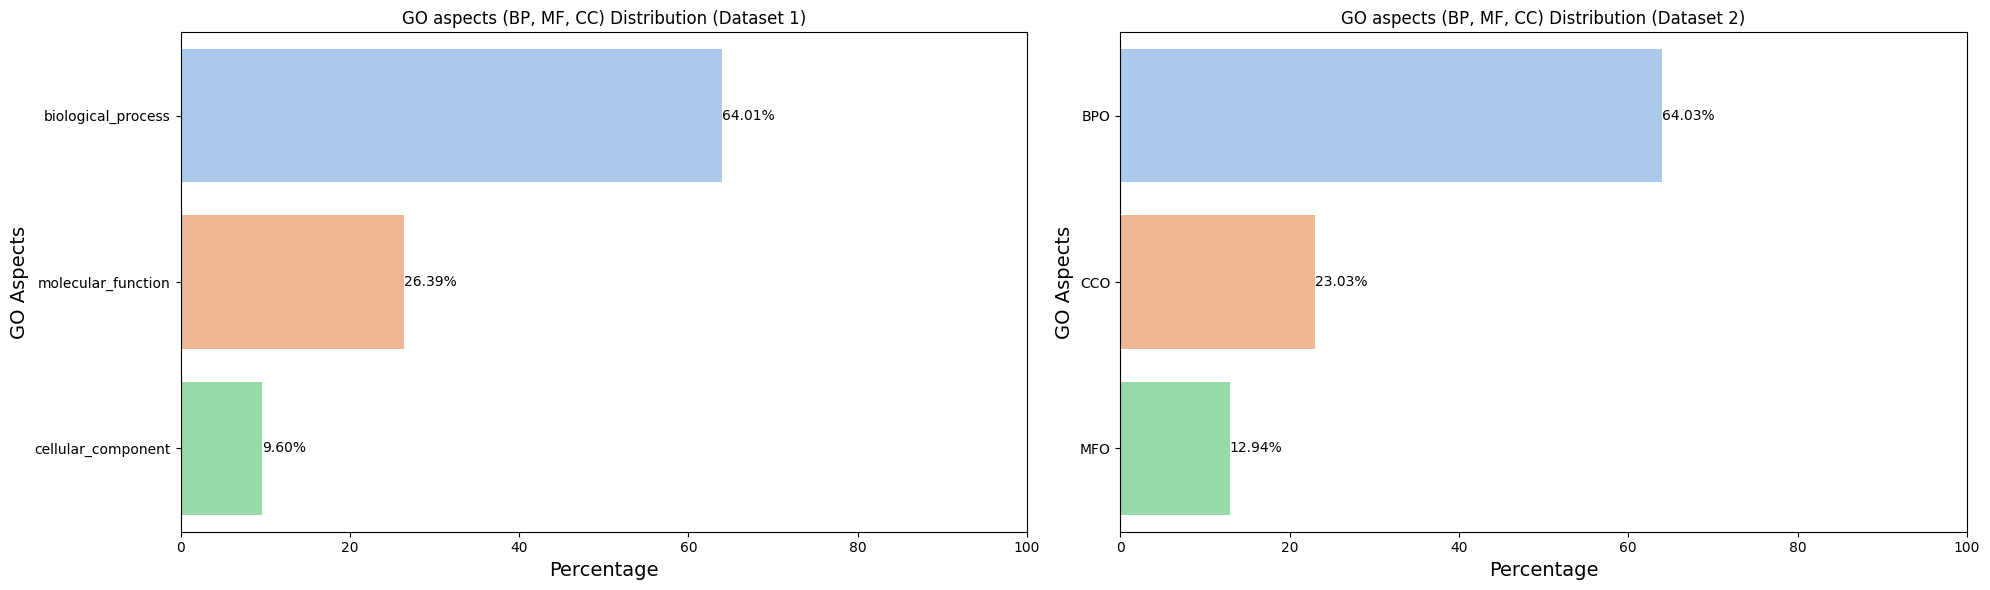

In [28]:
plot_ratio_compare(go_df, associations_df)

### Load (filtered) Sequences and Parse

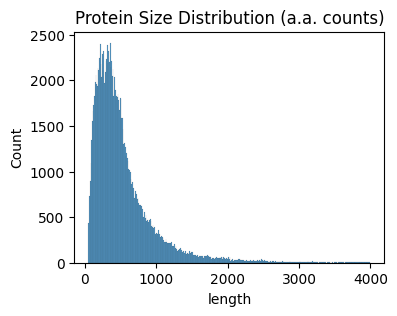

Sequences df dims: (140233, 3)
     uniprot_id                                           sequence  length
587  A0A0G2K6R9  MMNEDAAQKSDSGEKFNGSSQRRKRPKKSDSNASFLRAARAGNLDK...    3998
588  A0A2R8Q1V0  MGRFTIYRVLKKSGLSGLKVLKPQKCSFQPCSNTLTYTCQDCICYN...    3997
589      Q9Y4D8  MPANHLPIGSTMSTVHLSSDGTYFYWIWSPASLNEKTPKGHSVFMD...    3996
590  A0A5F9ZH30  MTTMLQKSDSNASFLRAARAGNLDKVVEYLKGGIDINTCNQNGLNA...    3995
591      Q80TY5  MLESYVTPILMSYVNRYIKNLKPSDLQLSLWGGDVVLSKLELKLDV...    3993


In [29]:
# Load and parse sequences from CAFA5

file_path = root / "cafa/train_sequences.fasta"
min_length = 50  # Minimum length threshold
max_length = 4000  # Maximum length threshold
valid_uniprot_ids = associations_df["uniprot_id"].to_numpy()

# Load sequences and build df
sequences = []
for record in SeqIO.parse(file_path, "fasta"):
    sequences.append(
        {
            "uniprot_id": record.id,
            "sequence": str(record.seq),
            "length": len(record.seq),
        }
    )

# Convert list of dictionaries to DataFrame
sequences_df = pd.DataFrame(sequences)
sequences_df = sequences_df.sort_values(by="length", ascending=False).reset_index(
    drop=True
)

# Filter sequences based on length
sequences_df_filtered = sequences_df[
    (sequences_df["length"] <= max_length) & (sequences_df["length"] >= min_length)
]

# Filter out proteins with obsolete GO terms (assuming go_nodes is defined)
filtered_sequences_df = sequences_df_filtered[
    sequences_df_filtered["uniprot_id"].isin(valid_uniprot_ids)
].reset_index(drop=True)

# Plot histogram of protein sizes
plt.figure(figsize=(4, 3))
sns.histplot(sequences_df_filtered, x="length", binwidth=10).set(
    title="Protein Size Distribution (a.a. counts)"
)
plt.savefig(root / "cafa/cafa_protein_size_dist.png", dpi=300)
plt.show()

# Save the filtered data
sequences_df_filtered.to_csv(root / "cafa/sequences.csv", index=False)

print(f"Sequences df dims: {sequences_df_filtered.shape}")
print(sequences_df_filtered.head())

### Load PPI Data (DIP)

In [32]:
# Load PPI data (DIP human) and preprocess

# file_path = root / "dip/Hsapi20170205.txt"  # human PPI
file_path = root / "dip/Scere20170205.txt"  # yeast PPI
# file_path = root /"dip/Mmusc20170205.txt"  # mice PPI
# file_path = root / "dip/Ecoli20170205.txt"  # ecoli PPI

ppi_df = pd.read_csv(file_path, delimiter="\t", on_bad_lines="warn")

print(ppi_df.info())
print(ppi_df.head().to_markdown())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22977 entries, 0 to 22976
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   ID interactor A                  22977 non-null  object
 1   ID interactor B                  22977 non-null  object
 2   Alt. ID interactor A             22977 non-null  object
 3   Alt. ID interactor B             22977 non-null  object
 4   Alias(es) interactor A           22977 non-null  object
 5   Alias(es) interactor B           22977 non-null  object
 6   Interaction detection method(s)  22977 non-null  object
 7   Publication 1st author(s)        22977 non-null  object
 8   Publication Identifier(s)        22977 non-null  object
 9   Taxid interactor A               22977 non-null  object
 10  Taxid interactor B               22977 non-null  object
 11  Interaction type(s)              22977 non-null  object
 12  Source database(s)              

In [33]:
# Preprocess dataset

# Keep only relevant columns
ppi_df.drop(
    columns=[
        "Alt. ID interactor A",
        "Alt. ID interactor B",
        "Alias(es) interactor A",
        "Alias(es) interactor B",
        "Publication 1st author(s)",
        "Publication Identifier(s)",
        "Source database(s)",
        "Interaction identifier(s)",
        "Processing Status",
    ],
    inplace=True,
)


# Rename remaining columns
new_column_names = {
    "ID interactor A": "uniprot_id_A",
    "ID interactor B": "uniprot_id_B",
    "Interaction detection method(s)": "detection_method",
    "Taxid interactor A": "taxiID_A",
    "Taxid interactor B": "taxiID_B",
    "Interaction type(s)": "ppi_type",
    "Confidence value(s)": "confidence",
}

ppi_df.rename(columns=new_column_names, inplace=True)

# Reorder columns
ppi_df = ppi_df[
    [
        "uniprot_id_A",
        "uniprot_id_B",
        "ppi_type",
        "detection_method",
        "confidence",
        "taxiID_A",
        "taxiID_B",
    ]
]

# Format data

# Extract uniprot ids
ppi_df["uniprot_id_A"] = ppi_df["uniprot_id_A"].apply(extract_uniprot_ids)
ppi_df["uniprot_id_B"] = ppi_df["uniprot_id_B"].apply(extract_uniprot_ids)

# Extract methods
ppi_df["detection_method"] = ppi_df["detection_method"].apply(extract_methods)

# Extract taxIDs
ppi_df["taxiID_A"] = ppi_df["taxiID_A"].apply(extract_taxiIDs)
ppi_df["taxiID_B"] = ppi_df["taxiID_B"].apply(extract_taxiIDs)

# Extract PPI type
ppi_df["ppi_type"] = ppi_df["ppi_type"].apply(extract_ppi_type)

# Extract confidence score
ppi_df["confidence"] = ppi_df["confidence"].apply(extract_confidence_score)

# Remove PPI pairs of diferent organisms
ppi_df = ppi_df[ppi_df["taxiID_A"] == ppi_df["taxiID_B"]]
ppi_df.reset_index(drop=True, inplace=True)

# Filter out PPI pairs without associations (protein-GO)
unique_associations_protein_ids = associations_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_associations_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_associations_protein_ids))
]

# Remove self-loops (A = B)
ppi_df = ppi_df[(ppi_df["uniprot_id_A"] != ppi_df["uniprot_id_B"])]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = sequences_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]

# Handling NA values in uniprot IDs
# There are entries without reference to Uniprot IDs
print(
    "# of missing UniProt IDs (A, B):",
    (
        len(ppi_df[ppi_df["uniprot_id_A"].isna()]),
        len(ppi_df[ppi_df["uniprot_id_B"].isna()]),
    ),
)

# Drop NAs
ppi_df.dropna(inplace=True)

# Reset index and save processed df
ppi_df.reset_index(drop=True, inplace=True)
ppi_df.to_csv(species_folder / "datasets/ppi.csv", index=False)

print(f"PPI df shape: {ppi_df.shape}")
print(ppi_df.head().to_markdown())
ppi_df.describe()

# of missing UniProt IDs (A, B): (0, 0)
PPI df shape: (21076, 7)
|    | uniprot_id_A   | uniprot_id_B   | ppi_type                                                       | detection_method                                                                                                                                    | confidence   |   taxiID_A |   taxiID_B |
|---:|:---------------|:---------------|:---------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------|:-------------|-----------:|-----------:|
|  0 | P07278         | P06244         | physical association;physical interaction;genetic interference | two hybrid;two hybrid;two hybrid pooling approach;two hybrid;genetic interference;experimental interaction detection;anti tag coimmunoprecipitation | core         |       4932 |       4932 |
|  1 | P06782         | P38717         | phy

,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
count,21076,21076,21076,21076,21076,21076,21076
unique,3836,3729,26,978,2,1,1
top,Q02821,P00546,physical association,anti tag coimmunoprecipitation,,4932,4932
freq,108,126,13974,7027,16187,21076,21076


### Extract Metadata

In [34]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = ppi_df["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_types.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of detection methods
methods = ppi_df["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_methods.txt"
with open(file_path, "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

# of unique PPI detection methods: 53
['affinity chromatography technology', 'anti bait coimmunoprecipitation', 'anti tag coimmunoprecipitation', 'atomic force microscopy', 'atpase assay']
# of unique PPI types: 9
['association', 'covalent binding', 'direct interaction', 'enzymatic reaction', 'genetic interference', 'methylation reaction', 'phosphorylation reaction', 'physical association', 'physical interaction']


In [35]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 4476
# of PPIs: 21076
# of unique PPIs: 21073


### Build NetworkX Graph to Extract LCC

In [36]:
# Construct nx graph to extract LCC

# Create undirected graph instance
ppi_graph = nx.Graph()

# Add edges
ppi_graph.add_edges_from(ppi_unique_pairs)

# Get connected components and lcc
cc = list(nx.connected_components(ppi_graph))
lcc = max(cc, key=len)

# Extract subgraph with lcc
ppi_graph_lcc = ppi_graph.subgraph(lcc).copy()

# Extract nodes and edges for graph dataset
ppi_nodes = ppi_graph_lcc.nodes()
ppi_edges = list(ppi_graph_lcc.edges())

# print-out basic graph attributes
print(f"# of nodes: {ppi_graph.number_of_nodes()}")
print(f"# of edges: {ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(ppi_graph_lcc)}")
print(f"\n# of connected components: {len(cc)}")
print(f"\n# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(ppi_graph_lcc)}")

# of nodes: 4476
# of edges: 21073
Is connected?: True

# of connected components: 19

# of nodes (LCC): 4439
# of edges (LCC): 21054
Is connected? (LCC): True


In [37]:
# PPI counts

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)
# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 4476
# of unique PPIs: 21073


In [38]:
# Filter protein-go associations with LCC nodes

# Keep full protein-GO associations for plotting
associations_full = associations_df.copy()

# Remove associations with large proteins
associations_df = associations_df[
    associations_df["uniprot_id"].isin(list(ppi_graph_lcc.nodes()))
].copy()

associations_df = associations_df[
    associations_df["uniprot_id"].isin(sequences_df_filtered["uniprot_id"].unique())
]
associations_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = species_folder / "datasets/associations.tsv"
associations_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_df['uniprot_id'].unique())}")
associations_df.head()

Filtered Protein-GO associations dims: (249129, 3)
# of unique UniProt IDs: 4431


,uniprot_id,go_id,aspect
0,O13297,GO:0008152,BPO
1,O13297,GO:0006357,BPO
2,O13297,GO:0006397,BPO
3,O13297,GO:0034243,BPO
4,O13297,GO:0065007,BPO


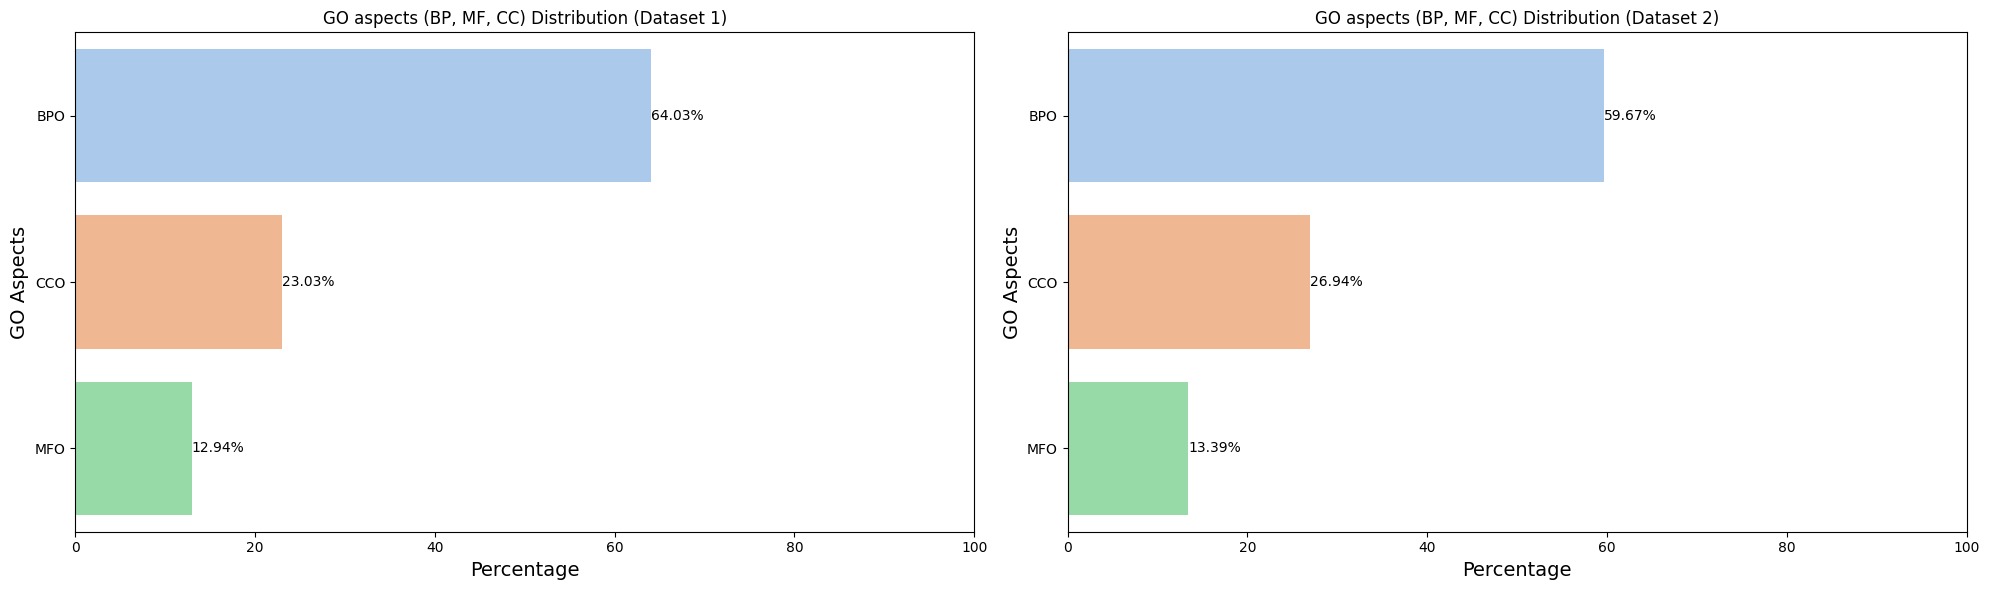

In [39]:
plot_ratio_compare(associations_full, associations_df)

### Build PPI Graph

In [40]:
# Load embeddings

emb_dataset = ProteinEmbeddingDataset(root / "cafa/protein_embeddings")

print(f"# of protein embeddings: {len(emb_dataset)}")

# of protein embeddings: 140233


In [41]:
# Collect uniprot ids and embeddings from Dataloader

# iterates over dataset in batches to extract sequences and ids
protein_embed_dict = {}
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

loader = DataLoader(emb_dataset, batch_size=1, shuffle=False)
for batch in tqdm(loader, total=len(loader), desc="Loading Protein Dataset..."):
    uniprot_id = str(batch["uniprot_id"][0])
    if batch["uniprot_id"][0] in unique_proteins_lcc_cafa:
        protein_embed_dict[batch["uniprot_id"][0]] = batch["tensor"].numpy().flatten()

# Save protein embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(protein_embed_dict, file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

Loading Protein Dataset...:   0%|          | 0/140233 [00:00<?, ?it/s]

# of protein ids: 4431
protein feats shape: torch.Size([4431, 1024])
key: P23201, value: 0
key: P23201, value: torch.Size([1024])


In [42]:
# Load protein embeddings dict

# Get unique protein ids
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

# Load embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "rb") as file:
    protein_embed_dict = pickle.load(file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

# of protein ids: 4431
protein feats shape: torch.Size([4431, 1024])
key: P23201, value: 0
key: P23201, value: torch.Size([1024])


In [43]:
# Creates edge_index

# Extracts PPI pairs for edge construction

# Ensures that every pair of nodes intersect PPI / CAFA5
edges_to_tensor = [
    [protein_ids_map[e[0]], protein_ids_map[e[1]]]
    for e in ppi_edges
    if e[0] in unique_proteins_lcc_cafa and e[1] in unique_proteins_lcc_cafa
]

edge_index_ppi = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_ppi.shape}")
edge_index_ppi

edge_index shape: torch.Size([2, 20964])


tensor([[1750, 1750, 1750,  ..., 1546, 2921, 3859],
        [2794, 2440,  104,  ..., 2761, 1182, 2409]])

In [44]:
# Creates torch geometric Data object and save

ppi_data = Data()
ppi_data.x = protein_feats
ppi_data.edge_index = edge_index_ppi

save_file_path = species_folder / "datasets/ppi_dataset.pt"
torch.save(ppi_data, save_file_path)
ppi_data

Data(x=[4431, 1024], edge_index=[2, 20964])

## Prepare PPI-GO Heterodata

#### Mapping Protein and GO ids to Unique Integer Indices

In [45]:
# Map GO terms and Uniprot IDs to respective indexes

# Map go ids
associations_df["go_idx"] = associations_df["go_id"].map(go_ids_map)

# Map proteins ids
associations_df["uniprot_idx"] = associations_df["uniprot_id"].map(protein_ids_map)

# Save
associations_df.to_csv(species_folder / "datasets/associations_indices.csv", index=False)

associations_df

,uniprot_id,go_id,aspect,go_idx,uniprot_idx
0,O13297,GO:0008152,BPO,5207,1367
1,O13297,GO:0006357,BPO,4137,1367
2,O13297,GO:0006397,BPO,4161,1367
3,O13297,GO:0034243,BPO,15140,1367
4,O13297,GO:0065007,BPO,27192,1367
...,...,...,...,...,...
249124,Q9URQ3,GO:0003674,MFO,2367,2896
249125,Q9URQ3,GO:0004000,MFO,2550,2896
249126,Q9URQ3,GO:0016787,MFO,9028,2896
249127,Q9URQ3,GO:0016814,MFO,9048,2896


#### Creating Protein-GO Positive Edges Index

In [46]:
# Create inter graph edges (UniProt -> GO)

edge_index_protgo_positive = torch.tensor(
    [
        associations_df["uniprot_idx"].values,
        associations_df["go_idx"].values,
    ],
    dtype=torch.long,
)

print(
    f"Protein associates with GO edge index shape: {edge_index_protgo_positive.shape}"
)
edge_index_protgo_positive

Protein associates with GO edge index shape: torch.Size([2, 249129])


tensor([[1367, 1367, 1367,  ..., 2896, 2896, 2896],
        [5207, 4137, 4161,  ..., 9028, 9048, 3534]])

#### Creating Protein-GO Negative Edges Index

In [47]:
# Negative sampling

print("Feasible?:", structured_negative_sampling_feasible(edge_index_protgo_positive))

edge_index_protgo_negative, associations_negative_df = generate_negative_edges(
    edge_index=edge_index_protgo_positive,
    num_nodes_protein=len(protein_ids),
    num_nodes_go=len(go_ids),
    num_neg_samples=edge_index_protgo_positive.shape[1] * 2,
    protein_mapping=protein_ids_map,
    go_mapping=go_ids_map,
    weighted=True,
    random_state=42,
)

print(
    f"Protein negative associates with GO edge index shape: {edge_index_protgo_negative.shape}"
)

display(associations_negative_df)
edge_index_protgo_negative

Feasible?: True
Protein negative associates with GO edge index shape: torch.Size([2, 498258])


,uniprot_id,go_id,uniprot_idx,go_idx
0,P53276,GO:0070516,3430,27658
1,P36517,GO:0043332,3809,18544
2,P32324,GO:0016036,3085,8513
3,P38064,GO:0006119,4333,3979
4,P38141,GO:0090271,3371,30317
...,...,...,...,...
498253,P33202,GO:0043954,197,19058
498254,Q12136,GO:0050679,2209,23628
498255,P38962,GO:0050864,3621,23765
498256,Q12246,GO:0031578,79,12731


tensor([[ 3430,  3809,  3085,  ...,  3621,    79,  3297],
        [27658, 18544,  8513,  ..., 23765, 12731, 40091]])

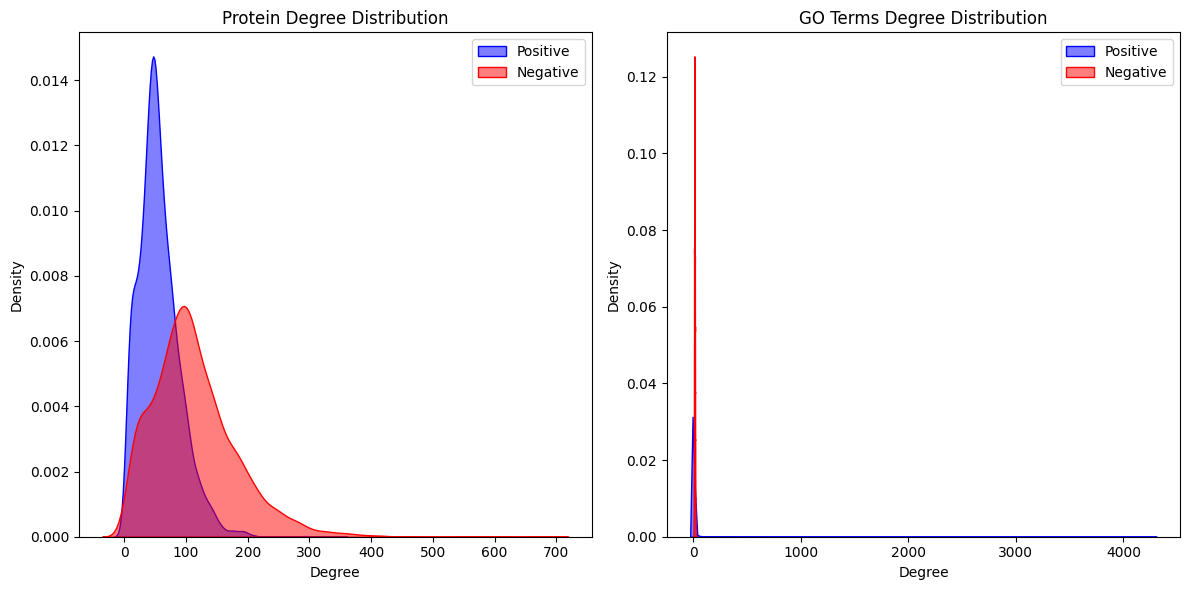

In [48]:
check_balance(
    edge_index_protgo_positive,
    edge_index_protgo_negative,
    len(protein_ids),
    len(go_ids),
)

#### Creating protein-GO Heterodata

In [49]:
# Create heterodata Protein-GO

# Concatenate edge indices
edge_index_protgo = torch.cat(
    (edge_index_protgo_positive, edge_index_protgo_negative), dim=1
)

# Labels for edges
positive_labels = torch.ones(edge_index_protgo_positive.shape[1], dtype=torch.float32)
negative_labels = torch.zeros(edge_index_protgo_negative.shape[1], dtype=torch.float32)
edge_labels = torch.cat((positive_labels, negative_labels), dim=0)

print(f"Protein GO edge index shape: {edge_index_protgo.shape}")
print("Edge Labels shape:", edge_labels.shape)

# Initialize HeteroData
hetero_data = HeteroData()

# Add nodes' features
hetero_data["protein"].x = protein_feats  # [num_proteins, num_features_proteins]
hetero_data["go"].x = go_feats  # [num_go_terms, num_features_go_terms]

# Add node's ids
hetero_data["protein"].id = protein_ids
hetero_data["go"].id = go_ids

# Add edges (intra and inter graph edges)

# Add edges (intra and inter graph edges)
hetero_data["protein", "ppi", "protein"].edge_index = edge_index_ppi
hetero_data["go", "relation", "go"].edge_index = edge_index_go
hetero_data["protein", "associates_with", "go"].edge_index = edge_index_protgo


# Add edge labels for protein-GO associations
hetero_data["protein", "associates_with", "go"].edge_label = edge_labels

print(hetero_data)

Protein GO edge index shape: torch.Size([2, 747387])
Edge Labels shape: torch.Size([747387])
HeteroData(
  protein={
    x=[4431, 1024],
    id=[4431],
  },
  go={
    x=[42255, 384],
    id=[42255],
  },
  (protein, ppi, protein)={ edge_index=[2, 20964] },
  (go, relation, go)={ edge_index=[2, 81848] },
  (protein, associates_with, go)={
    edge_index=[2, 747387],
    edge_label=[747387],
  }
)


In [50]:
# Masking edges in heterodata in protein-group wise manner

# Get the number of inter-edges
num_edges = hetero_data["protein", "associates_with", "go"].edge_index.size(1)

# Obtain unique proteins and their edge indices
unique_proteins, edge_positions = torch.unique(
    hetero_data["protein", "associates_with", "go"].edge_index[0], return_inverse=True
)

# Shuffle protein indices for random splitting
permuted_indices = torch.randperm(unique_proteins.size(0))
num_proteins = unique_proteins.size(0)
train_end = int(num_proteins * 0.8)
val_end = int(num_proteins * 0.9)

# Split proteins into groups and add extra dim for broadcasting
train_proteins = permuted_indices[:train_end].unsqueeze(1)
val_proteins = permuted_indices[train_end:val_end].unsqueeze(1)
test_proteins = permuted_indices[val_end:].unsqueeze(1)

# Create masks for each dataset
train_mask = edge_positions.unsqueeze(0).eq(train_proteins).any(0)
val_mask = edge_positions.unsqueeze(0).eq(val_proteins).any(0)
test_mask = edge_positions.unsqueeze(0).eq(test_proteins).any(0)

# Storing masks directly into HeteroData for easy access later
hetero_data["protein", "associates_with", "go"]["train_mask"] = train_mask
hetero_data["protein", "associates_with", "go"]["val_mask"] = val_mask
hetero_data["protein", "associates_with", "go"]["test_mask"] = test_mask

# Check data
# get edges
edge_index = hetero_data["protein", "associates_with", "go"].edge_index
edge_labels = hetero_data["protein", "associates_with", "go"].edge_label

# Apply masks
train_edges = edge_index[:, train_mask]
train_labels = edge_labels[train_mask]

val_edges = edge_index[:, val_mask]
val_labels = edge_labels[val_mask]

test_edges = edge_index[:, test_mask]
test_labels = edge_labels[test_mask]

print("Training Edges Count:", train_edges.size(1))
print("Validation Edges Count:", val_edges.size(1))
print("Testing Edges Count:", test_edges.size(1))

# Plot label distribution
train_label_ratio = torch.sum(train_labels) / train_labels.size(0)
val_label_ratio = torch.sum(val_labels) / val_labels.size(0)
test_label_ratio = torch.sum(test_labels) / test_labels.size(0)

# Save HeteroData
save_file_path = species_folder / "datasets" / "heterodata.pt"
torch.save(hetero_data, save_file_path)


print(
    f"Labels (ratio): train ({train_label_ratio:.2f}), val ({val_label_ratio:.2f}), test ({test_label_ratio:.2f})"
)
print()
print(hetero_data)

Training Edges Count: 598873
Validation Edges Count: 72402
Testing Edges Count: 76112
Labels (ratio): train (0.33), val (0.33), test (0.33)

HeteroData(
  protein={
    x=[4431, 1024],
    id=[4431],
  },
  go={
    x=[42255, 384],
    id=[42255],
  },
  (protein, ppi, protein)={ edge_index=[2, 20964] },
  (go, relation, go)={ edge_index=[2, 81848] },
  (protein, associates_with, go)={
    edge_index=[2, 747387],
    edge_label=[747387],
    train_mask=[747387],
    val_mask=[747387],
    test_mask=[747387],
  }
)


## Training

### SAGEConv Model

#### SAGEConv Model Class with 2 GAT layers

In [ ]:
class HGNNSAGE(torch.nn.Module):
    def __init__(self, protein_features, go_features, out_features):
        super(HGNNSAGE, self).__init__()

        # Initialize SAGEConv layers for each type of connection
        self.conv1_protein = SAGEConv(protein_features, out_features)
        self.conv1_go = SAGEConv(go_features, out_features)
        self.conv2_protein = SAGEConv(out_features, out_features)
        self.conv2_go = SAGEConv(out_features, out_features)

        # Dropout layer
        self.dropout = Dropout(p=0.5)

        # Linear layer for making predictions
        self.protein_to_go = Linear(out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply dropout
        x_protein = self.dropout(x_protein)
        x_go = self.dropout(x_go)

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[
            edge_index_protein_go[0]
        ]  # Source protein features
        go_features = x_go[edge_index_protein_go[1]]  # Target GO features

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores


model = HGNNSAGE(protein_features=1024, go_features=384, out_features=512)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, "min", patience=10, factor=0.1, verbose=True
)
early_stopping_patience = 20  # Set patience for early stopping

#### Optimizer and Scheduler

In [ ]:
model = HGNNSAGE(protein_features=1024, go_features=384, out_features=512)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, "min", patience=10, factor=0.1, verbose=True
)
early_stopping_patience = 20  # Set patience for early stopping

#### Evaluation Functions

In [ ]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask):
    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        val_loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask].cpu())
        predictions = out.sigmoid()
        val_auroc = roc_auc_score(
            edge_labels[val_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )
    return val_loss.item(), val_auroc


def predict(model, x_dict, edge_index_dict, edge_labels, test_mask):
    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, test_mask)
        predictions = out.sigmoid()
        test_labels = edge_labels[test_mask].to(predictions.device)
        auroc = roc_auc_score(
            test_labels.cpu().detach().numpy(), predictions.cpu().detach().numpy()
        )
        predicted_classes = (predictions > 0.5).float()
        balanced_accuracy = balanced_accuracy_score(
            test_labels.cpu().detach().numpy(), predicted_classes.cpu().detach().numpy()
        )
        return predicted_classes, test_labels, auroc, balanced_accuracy

#### Training Function

In [ ]:
def train(
    model,
    optimizer,
    x_dict,
    edge_index_dict,
    edge_labels,
    train_mask,
    val_mask=None,
    epochs=50,
    save_path="saved_models/",
):
    best_val_auroc = 0
    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }
    os.makedirs(save_path, exist_ok=True)
    epochs_no_improve = 0
    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        optimizer.zero_grad()
        out = model(x_dict, edge_index_dict, train_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[train_mask])
        loss.backward()
        optimizer.step()
        predictions = out.sigmoid()
        train_auroc = roc_auc_score(
            edge_labels[train_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )
        metrics["train_losses"][epoch] = loss.item()
        metrics["train_aurocs"][epoch] = train_auroc
        if val_mask is not None:
            val_loss, val_auroc = evaluate(
                model, x_dict, edge_index_dict, edge_labels, val_mask
            )
            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc
            if val_auroc > best_val_auroc:
                best_val_auroc = val_auroc
                model_path = os.path.join(save_path, "best_model.pt")
                model_params_path = os.path.join(save_path, "best_model_params.pt")
                torch.save(model, model_path)
                torch.save(model.state_dict(), model_params_path)
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
            if epochs_no_improve >= early_stopping_patience:
                print(
                    f"Early stopping at epoch {epoch} with best validation AUROC: {best_val_auroc:.3f}"
                )
                break
        scheduler.step(val_loss)
        if epoch % 10 == 0:
            print(
                f"Epoch {epoch}: Avg Training Loss: {sum(metrics['train_losses'].values())/len(metrics['train_losses']):.3f}"
            )
            print(
                f"  Avg Training AUROC: {sum(metrics['train_aurocs'].values())/len(metrics['train_aurocs']):.3f}"
            )
            if val_mask is not None:
                print(
                    f"  Avg Validation Loss: {sum(metrics['val_losses'].values())/len(metrics['val_losses']):.3f}"
                )
                print(
                    f"  Avg Validation AUROC: {sum(metrics['val_aurocs'].values())/len(metrics['val_aurocs']):.3f}"
                )
                print(
                    f"New best model saved with validation AUROC: {best_val_auroc:.3f}"
                )
    return metrics


print(model)
print("Model's state_dict:")
for param_tensor in model.state_dict():
    print(param_tensor, "\t", model.state_dict()[param_tensor].size())
print("Optimizer's state_dict:")
for var_name in optimizer.state_dict():
    print(var_name, "\t", optimizer.state_dict()[var_name])

In [ ]:
# Training

metrics_dict = train(
    model=model,
    optimizer=optimizer,
    x_dict=hetero_data.x_dict,
    edge_index_dict=hetero_data.edge_index_dict,
    edge_labels=hetero_data["protein", "associates_with", "go"].edge_label,
    train_mask=train_mask,
    val_mask=val_mask,
    epochs=250,
    save_path="saved_models/",
)

plot_loss_and_accuracy(metrics_dict)

In [ ]:
# Testing

# Extract test mask
test_mask = hetero_data["protein", "associates_with", "go"].test_mask

predicted_labels, test_labels, test_auroc, test_bal_accuracy = predict(
    model,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label,
    test_mask,
)

print(f"AUROC test: {test_auroc}")
print(f"Balanced accuracy test: {test_bal_accuracy}")

print(classification_report(test_labels, predicted_labels, target_names=["0", "1"]))


disp = ConfusionMatrixDisplay.from_predictions(
    test_labels, predicted_labels, normalize="true", cmap="Blues", values_format=".1%"
)
plt.show()

In [ ]:
# Load best model

model.load_state_dict(torch.load(root / "saved_models/best_model_params.pt"))
model

In [ ]:
# Testing

# Extract test mask
test_mask = hetero_data["protein", "associates_with", "go"].test_mask

predicted_labels, test_labels, test_auroc, test_bal_accuracy = predict(
    model,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label,
    test_mask,
)

print(f"AUROC test: {test_auroc}")
print(f"Balanced accuracy test: {test_bal_accuracy}")

print(classification_report(test_labels, predicted_labels, target_names=["0", "1"]))

disp = ConfusionMatrixDisplay.from_predictions(
    test_labels, predicted_labels, normalize="true", cmap="Blues", values_format=".1%"
)
plt.show()

### GAT Model GPU

In [ ]:
# Move hetero_data to GPU
hetero_data = hetero_data.to(device)


# Extract edges and labels using masks
def get_edge_data(mask):
    edge_index = hetero_data["protein", "associates_with", "go"].edge_index[:, mask]
    edge_label = hetero_data["protein", "associates_with", "go"].edge_label[mask]
    return edge_index, edge_label


train_edges, train_labels = get_edge_data(
    hetero_data["protein", "associates_with", "go"]["train_mask"]
)
val_edges, val_labels = get_edge_data(
    hetero_data["protein", "associates_with", "go"]["val_mask"]
)
test_edges, test_labels = get_edge_data(
    hetero_data["protein", "associates_with", "go"]["test_mask"]
)

In [ ]:
from torch_geometric.loader import NeighborSampler

# Create a NeighborSampler for training, validation, and test sets
train_loader = NeighborSampler(
    hetero_data.edge_index_dict[("protein", "associates_with", "go")],
    node_idx=train_mask.nonzero(as_tuple=True)[0],
    sizes=[10, 10],  # Number of neighbors to sample at each layer
    batch_size=1024,
    shuffle=True,
    num_workers=4,
)

val_loader = NeighborSampler(
    hetero_data.edge_index_dict[("protein", "associates_with", "go")],
    node_idx=val_mask.nonzero(as_tuple=True)[0],
    sizes=[10, 10],
    batch_size=1024,
    shuffle=False,
    num_workers=4,
)

test_loader = NeighborSampler(
    hetero_data.edge_index_dict[("protein", "associates_with", "go")],
    node_idx=test_mask.nonzero(as_tuple=True)[0],
    sizes=[10, 10],
    batch_size=1024,
    shuffle=False,
    num_workers=4,
)

In [ ]:
class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        final_out_features = out_features if concat else per_head_features
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, batch_size, mask=None):
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

In [ ]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_loader):
    model.eval()
    total_loss = 0
    total_auroc = 0
    with torch.no_grad():
        for batch_size, n_id, adjs in val_loader:
            adjs = [adj.to(device) for adj in adjs]

            out = model(x_dict, edge_index_dict, batch_size)
            val_loss = F.binary_cross_entropy_with_logits(
                out, edge_labels[n_id].to(device)
            )
            predictions = out.sigmoid()

            val_auroc = roc_auc_score(
                edge_labels[n_id].cpu().detach().numpy(),
                predictions.cpu().detach().numpy(),
            )

            total_loss += val_loss.item()
            total_auroc += val_auroc

    avg_val_loss = total_loss / len(val_loader)
    avg_val_auroc = total_auroc / len(val_loader)
    return avg_val_loss, avg_val_auroc

In [ ]:
model = HGNNGAT(
    protein_features=64, go_features=64, out_features=256, dropout=0.4, heads=8
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, "min", patience=10, factor=0.1, verbose=True
)

In [ ]:
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from pathlib import Path


def train(
    model,
    optimizer,
    train_loader,
    x_dict,
    edge_index_dict,
    edge_labels,
    epochs,
    val_loader=None,
    save_path=None,
    patience=10,
):
    best_val_loss = float("inf")
    best_val_auroc = 0
    early_stopping_counter = 0

    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path) / "models"
    save_path.mkdir(parents=True, exist_ok=True)

    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        total_loss = 0
        total_auroc = 0
        for batch_size, n_id, adjs in train_loader:
            optimizer.zero_grad()
            adjs = [adj.to(device) for adj in adjs]

            out = model(x_dict, edge_index_dict, batch_size)
            loss = F.binary_cross_entropy_with_logits(out, edge_labels[n_id].to(device))
            loss.backward()
            optimizer.step()

            predictions = out.sigmoid()
            train_auroc = roc_auc_score(
                edge_labels[n_id].cpu().detach().numpy(),
                predictions.cpu().detach().numpy(),
            )

            total_loss += loss.item()
            total_auroc += train_auroc

        avg_train_loss = total_loss / len(train_loader)
        avg_train_auroc = total_auroc / len(train_loader)

        metrics["train_losses"][epoch] = avg_train_loss
        metrics["train_aurocs"][epoch] = avg_train_auroc

        if val_loader is not None:
            val_loss, val_auroc = evaluate(
                model, x_dict, edge_index_dict, edge_labels, val_loader
            )

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                best_weights_path = save_path / "best_model_weights.pt"
                torch.save(model.state_dict(), best_weights_path)
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(f"  Avg Training Loss: {avg_train_loss:.3f}")
            print(f"  Avg Training AUROC: {avg_train_auroc:.3f}")
            if val_loader is not None:
                print(
                    f"  Avg Validation Loss: {sum(metrics['val_losses'].values())/len(metrics['val_losses']):.3f}"
                )
                print(
                    f"  Avg Validation AUROC: {sum(metrics['val_aurocs'].values())/len(metrics['val_aurocs']):.3f}"
                )
                print(
                    f"New best model saved with validation AUROC: {best_val_auroc:.3f}"
                )

    final_weights_path = save_path / "final_model_weights.pt"
    torch.save(model.state_dict(), final_weights_path)

    return metrics

In [ ]:
metrics_dict = train(
    model,
    optimizer,
    train_loader,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label.to(device),
    250,
    val_loader,
    species_folder,
    50,
)

plot_loss_and_accuracy(metrics_dict, species_folder)

### GAT Model CPU

In [ ]:
class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Linear layers for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[
            edge_index_protein_go[0]
        ]  # Source protein features
        go_features = x_go[edge_index_protein_go[1]]  # Target GO features

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

#### Optimizer and Scheduler

In [ ]:
model = HGNNGAT(
    protein_features=1024, go_features=384, out_features=512, dropout=0.6, heads=8
)

# Training loop
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    "min",
    patience=10,
    factor=0.1,
    verbose=True,
)

#### Training Function

In [ ]:
def train(
    model,
    optimizer,
    x_dict,
    edge_index_dict,
    edge_labels,
    train_mask,
    epochs,
    val_mask=None,
    save_path=None,
    patience=10,
):
    best_val_loss = float("inf")  # Initialize the best validation loss to a large value
    best_val_auroc = 0  # Initialize the best validation AUROC
    early_stopping_counter = 0  # Counter for early stopping

    # Initialize dictionaries to keep training metrics
    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path) / "models"
    save_path.mkdir(
        parents=True, exist_ok=True
    )  # Ensure the save directory for models exists

    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        optimizer.zero_grad()

        out = model(x_dict, edge_index_dict, train_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[train_mask])

        loss.backward()
        optimizer.step()

        predictions = out.sigmoid()
        train_auroc = roc_auc_score(
            edge_labels[train_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )

        metrics["train_losses"][epoch] = loss.item()
        metrics["train_aurocs"][epoch] = train_auroc

        if val_mask is not None:
            val_loss, val_auroc = evaluate(
                model, x_dict, edge_index_dict, edge_labels, val_mask
            )

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                best_weights_path = save_path / "best_model_weights.pt"
                torch.save(model.state_dict(), best_weights_path)
                early_stopping_counter = 0  # Reset counter
            else:
                early_stopping_counter += 1  # Increment counter

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(
                f"  Avg Training Loss: {sum(metrics['train_losses'].values())/len(metrics['train_losses']):.3f}"
            )
            print(
                f"  Avg Training AUROC: {sum(metrics['train_aurocs'].values())/len(metrics['train_aurocs']):.3f}"
            )
            if val_mask is not None:
                print(
                    f"  Avg Validation Loss: {sum(metrics['val_losses'].values())/len(metrics['val_losses']):.3f}"
                )
                print(
                    f"  Avg Validation AUROC: {sum(metrics['val_aurocs'].values())/len(metrics['val_aurocs']):.3f}"
                )
                print(
                    f"New best model saved with validation AUROC: {best_val_auroc:.3f}"
                )

    final_weights_path = save_path / "final_model_weights.pt"
    torch.save(model.state_dict(), final_weights_path)

    return metrics


print(model)
print("Model's state_dict:")
for param_tensor in model.state_dict():
    print(param_tensor, "\t", model.state_dict()[param_tensor].size())

#### Train

In [ ]:
metrics_dict = train(
    model,
    optimizer,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label,
    train_mask,
    250,
    val_mask,
    species_folder,
    50,
)

plot_loss_and_accuracy(metrics_dict, species_folder)

#### Predict

In [ ]:
# Load final model

model.load_state_dict(torch.load(species_folder / "models" / "final_model_weights.pt"))
model

In [ ]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

In [ ]:
# Load best training model

model.load_state_dict(torch.load(species_folder / "models" / "best_model_weights.pt"))
model

In [ ]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

In [ ]:
test_results[test_results["Ground Truth Label"] == test_results["Predicted Label"]]

In [ ]:
test_results[
    (test_results["Ground Truth Label"] == 0.0)
    & (test_results["Predicted Label"] == 1.0)
].sort_values(by="Probability", ascending=False).head(20)

**Important Notes**

- some GO terms are hard probabably because, for example, negative regulation of transcription doesnt rely necessarily on the sequence of the protein but the context. Thus, a PPI network is the only way to provide such information easily.
- **Multi-Species PPI**; connect species through a node corresponding to the closest species (taxon). This might allow flow of evolutionary information defined a priori. On the other hand, use multiple PPI networks connected to the go graph.
  - the supernode and edges connecting species could be a special edge aggregating information from two species concatenated and processed by these nodes / edges
  - Is this capable of predicting new pathways throughout evolution?

In [ ]:
print(go_df[go_df["go_id"] == "GO:0018197"].to_markdown())

In [ ]:
# Evaluate one protein

protein = test_results["Protein ID"][100]

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label", "Predicted Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Predicted Label"])
    .sort_index()
)

### GAT Model CPU - Explainer

#### Handling Attention Weights

In [ ]:
def aggregate_attention_weights(attn_weights, edge_index, num_nodes):
    # Initialize node attention with zeros, matching the device of attn_weights
    node_attention = torch.zeros(
        (num_nodes, attn_weights.size(1)), device=attn_weights.device
    )

    # Print the shapes for debugging
    # print(f"attn_weights shape: {attn_weights.shape}")
    # print(f"edge_index shape: {edge_index.shape}")

    # Check if the dimensions match as expected
    assert edge_index.size(1) == attn_weights.size(
        0
    ), "Edge index and attention weights dimensions do not match"

    # Iterate over all edges
    for i in range(attn_weights.size(0)):
        src = edge_index[0, i].item()
        dst = edge_index[1, i].item()
        if src < num_nodes and dst < num_nodes:
            node_attention[src] += attn_weights[i]
            node_attention[dst] += attn_weights[i]
        else:
            print(
                f"Skipping out-of-bounds edge at index {i} with edge_index: {edge_index[:, i]}"
            )

    # Average the node attention by dividing by 2
    node_attention = node_attention / 2
    return node_attention

In [ ]:
class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout, add_self_loops=False
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Linear layers for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[
            edge_index_protein_go[0]
        ]  # Source protein features
        go_features = x_go[edge_index_protein_go[1]]  # Target GO features

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores


    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            # Apply the first convolution layer to protein and GO nodes
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            # Apply the second convolution layer
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            # # Debugging information
            # print(f"edge_index_protein_1 shape: {edge_index_protein_1.shape}")
            # print(f"attn_weights_protein_1 shape: {attn_weights_protein_1.shape}")
            # print(f"edge_index_go_1 shape: {edge_index_go_1.shape}")
            # print(f"attn_weights_go_1 shape: {attn_weights_go_1.shape}")
            # print(f"edge_index_protein_2 shape: {edge_index_protein_2.shape}")
            # print(f"attn_weights_protein_2 shape: {attn_weights_protein_2.shape}")
            # print(f"edge_index_go_2 shape: {edge_index_go_2.shape}")
            # print(f"attn_weights_go_2 shape: {attn_weights_go_2.shape}")

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [ ]:
class NormalizedGATConv(GATConv):
    def forward(self, x, edge_index, return_attention_weights=False):
        # Call the original forward method to compute attention
        out = super().forward(x, edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Normalize the attention coefficients
        alpha = alpha / alpha.sum(dim=1, keepdim=True)

        # If return_attention_weights is True, return x and alpha, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha)
        else:
            return x

class HGNNGATWithNormalizedAttention(torch.nn.Module):
    def __init__(self, protein_features, go_features, out_features, dropout=0.6, heads=8, concat=True):
        super(HGNNGATWithNormalizedAttention, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = NormalizedGATConv(protein_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv1_go = NormalizedGATConv(go_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_protein = NormalizedGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_go = NormalizedGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        final_out_features = out_features if concat else per_head_features
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        x_protein = F.elu(self.conv1_protein(x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")]))
        x_protein = F.elu(self.conv2_protein(x_protein, edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))
        
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )


In [ ]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask):
    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask])
        predictions = out.sigmoid()
        auroc = roc_auc_score(
            edge_labels[val_mask].cpu().numpy(), predictions.cpu().numpy()
        )
    return loss.item(), auroc

In [ ]:
def train(
    model,
    optimizer,
    x_dict,
    edge_index_dict,
    edge_labels,
    train_mask,
    epochs,
    val_mask=None,
    save_path=None,
    patience=10,
):
    best_val_loss = float("inf")  # Initialize the best validation loss to a large value
    best_val_auroc = 0  # Initialize the best validation AUROC
    early_stopping_counter = 0  # Counter for early stopping

    # Initialize dictionaries to keep training metrics
    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path) / "models"
    save_path.mkdir(
        parents=True, exist_ok=True
    )  # Ensure the save directory for models exists

    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        optimizer.zero_grad()

        out = model(x_dict, edge_index_dict, train_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[train_mask])

        loss.backward()
        optimizer.step()

        predictions = out.sigmoid()
        train_auroc = roc_auc_score(
            edge_labels[train_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )

        metrics["train_losses"][epoch] = loss.item()
        metrics["train_aurocs"][epoch] = train_auroc

        if val_mask is not None:
            val_loss, val_auroc = evaluate(
                model, x_dict, edge_index_dict, edge_labels, val_mask
            )

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                best_weights_path = save_path / "best_model_weights.pt"
                torch.save(model.state_dict(), best_weights_path)
                early_stopping_counter = 0  # Reset counter
            else:
                early_stopping_counter += 1  # Increment counter

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(
                f"  Avg Training Loss: {sum(metrics['train_losses'].values())/len(metrics['train_losses']):.3f}"
            )
            print(
                f"  Avg Training AUROC: {sum(metrics['train_aurocs'].values())/len(metrics['train_aurocs']):.3f}"
            )
            if val_mask is not None:
                print(
                    f"  Avg Validation Loss: {sum(metrics['val_losses'].values())/len(metrics['val_losses']):.3f}"
                )
                print(
                    f"  Avg Validation AUROC: {sum(metrics['val_aurocs'].values())/len(metrics['val_aurocs']):.3f}"
                )
                print(
                    f"New best model saved with validation AUROC: {best_val_auroc:.3f}"
                )

    final_weights_path = save_path / "final_model_weights.pt"
    torch.save(model.state_dict(), final_weights_path)

    return metrics


In [ ]:
def plot_loss_and_accuracy(metrics, save_path):
    epochs = list(metrics["train_losses"].keys())

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, list(metrics["train_losses"].values()), label="Training Loss")
    plt.plot(epochs, list(metrics["val_losses"].values()), label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, list(metrics["train_aurocs"].values()), label="Training AUROC")
    plt.plot(epochs, list(metrics["val_aurocs"].values()), label="Validation AUROC")
    plt.xlabel("Epoch")
    plt.ylabel("AUROC")
    plt.title("Training and Validation AUROC")
    plt.legend()

    plt.tight_layout()
    plt.savefig(Path(save_path) / "training_metrics.png")
    plt.show()

In [ ]:
def visualize_node_importance(attn_weights, node_type, id_mapping, top_n=10):
    # Average attention weights across heads
    avg_attn_weights = attn_weights.mean(dim=1).cpu().detach().numpy()
    top_indices = avg_attn_weights.argsort()[-top_n:][::-1]
    top_importances = avg_attn_weights[top_indices]

    # Map indices to IDs using the provided id_mapping
    top_ids = [id_mapping[idx] for idx in top_indices]

    plt.figure(figsize=(10, 6))
    plt.bar(range(top_n), top_importances, tick_label=top_ids)
    plt.xlabel(f"Top {top_n} {node_type} Node IDs")
    plt.ylabel("Importance")
    plt.title(f"Top {top_n} Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return top_ids

In [ ]:
model = HGNNGATWithNormalizedAttention(
    protein_features=1024, go_features=384, out_features=512, dropout=0.6, heads=8
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    "min",
    patience=10,
    factor=0.1,
    verbose=True,
)

metrics_dict = train(
    model,
    optimizer,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label,
    hetero_data["protein", "associates_with", "go"].train_mask,
    100,
    hetero_data["protein", "associates_with", "go"].val_mask,
    species_folder,
    25,
)

#### Predict

In [ ]:
# Load final model

model.load_state_dict(torch.load(species_folder / "models" / "final_model_weights.pt"))
model

In [ ]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

In [ ]:
if metrics_dict:
    plot_loss_and_accuracy(metrics_dict, species_folder)

    # Visualizing node importance
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    # Define the mappings (example mappings, replace with actual mappings)
    go_id_mapping = {
        index: go_id for index, go_id in enumerate(hetero_data["go"].id)
    }
    protein_id_mapping = {
        index: protein_id
        for index, protein_id in enumerate(hetero_data["protein"].id)
    }

    # Aggregate attention weights for proteins and GO terms using the correct edge indices
    protein_attention_1 = aggregate_attention_weights(
        attn_weights_protein_1, edge_index_protein_1, hetero_data["protein"].x.size(0)
    )
    protein_attention_2 = aggregate_attention_weights(
        attn_weights_protein_2, edge_index_protein_2, hetero_data["protein"].x.size(0)
    )
    go_attention_1 = aggregate_attention_weights(
        attn_weights_go_1, edge_index_go_1, hetero_data["go"].x.size(0)
    )
    go_attention_2 = aggregate_attention_weights(
        attn_weights_go_2, edge_index_go_2, hetero_data["go"].x.size(0)
    )

    # Visualize protein node importance
    top_protein_ids = visualize_node_importance(protein_attention_1, "Protein", protein_id_mapping)
    # Visualize GO term node importance
    top_go_ids = visualize_node_importance(go_attention_1, "GO Term", go_id_mapping)
else:
    print("Training did not complete correctly, no metrics to plot.")

print("Top Proteins by importance:")
print(top_protein_ids)
print("Top GO terms by importance:")
print(top_go_ids)

In [ ]:
# Load best training model

model.load_state_dict(torch.load(species_folder / "models" / "best_model_weights.pt"))
model

In [ ]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

In [ ]:
if metrics_dict:
    plot_loss_and_accuracy(metrics_dict, species_folder)

    # Visualizing node importance
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    # Define the mappings (example mappings, replace with actual mappings)
    go_id_mapping = {
        index: go_id for index, go_id in enumerate(hetero_data["go"].id)
    }
    protein_id_mapping = {
        index: protein_id
        for index, protein_id in enumerate(hetero_data["protein"].id)
    }

    # Aggregate attention weights for proteins and GO terms using the correct edge indices
    protein_attention_1 = aggregate_attention_weights(
        attn_weights_protein_1, edge_index_protein_1, hetero_data["protein"].x.size(0)
    )
    protein_attention_2 = aggregate_attention_weights(
        attn_weights_protein_2, edge_index_protein_2, hetero_data["protein"].x.size(0)
    )
    go_attention_1 = aggregate_attention_weights(
        attn_weights_go_1, edge_index_go_1, hetero_data["go"].x.size(0)
    )
    go_attention_2 = aggregate_attention_weights(
        attn_weights_go_2, edge_index_go_2, hetero_data["go"].x.size(0)
    )

    # Visualize protein node importance
    top_protein_ids = visualize_node_importance(protein_attention_1, "Protein", protein_id_mapping)
    # Visualize GO term node importance
    top_go_ids = visualize_node_importance(go_attention_1, "GO Term", go_id_mapping)
else:
    print("Training did not complete correctly, no metrics to plot.")


print("Top Proteins by importance:")
print(top_protein_ids)
print("Top GO terms by importance:")
print(top_go_ids)

In [ ]:
go_df[go_df["go_id"].isin(top_go_ids)]

In [ ]:
ppi_df[(ppi_df["uniprot_id_A"].isin(top_protein_ids[:1])) | ppi_df["uniprot_id_B"].isin(top_protein_ids[:1])]

In [ ]:
test_results[test_results["Ground Truth Label"] == test_results["Predicted Label"]]

In [ ]:
test_results[
    (test_results["Ground Truth Label"] == 0.0)
    & (test_results["Predicted Label"] == 1.0)
].sort_values(by="Probability", ascending=False).head(30)

In [ ]:
print(go_df[go_df["go_id"] == "GO:0045495"].to_markdown())

In [ ]:
# Evaluate one protein

protein = test_results["Protein ID"][100]

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label", "Predicted Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Predicted Label"])
    .sort_index()
)

### GAT Model CPU - Normalized Attention and Explainer

#### Handling Attention Weights

In [51]:
def aggregate_attention_weights(attn_weights, edge_index, num_nodes):
    # Initialize node attention with zeros, matching the device of attn_weights
    node_attention = torch.zeros(
        (num_nodes, attn_weights.size(1)), device=attn_weights.device
    )

    # Print the shapes for debugging
    # print(f"attn_weights shape: {attn_weights.shape}")
    # print(f"edge_index shape: {edge_index.shape}")

    # Check if the dimensions match as expected
    assert edge_index.size(1) == attn_weights.size(
        0
    ), "Edge index and attention weights dimensions do not match"

    # Iterate over all edges
    for i in range(attn_weights.size(0)):
        src = edge_index[0, i].item()
        dst = edge_index[1, i].item()
        if src < num_nodes and dst < num_nodes:
            node_attention[src] += attn_weights[i]
            node_attention[dst] += attn_weights[i]
        else:
            print(
                f"Skipping out-of-bounds edge at index {i} with edge_index: {edge_index[:, i]}"
            )

    # Average the node attention by dividing by 2
    node_attention = node_attention / 2
    return node_attention

In [58]:
class NormGATConv(GATConv):
    def forward(self, x, edge_index, return_attention_weights=False):
        # Call the original forward method to compute attention
        out = super().forward(x, edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Normalize the attention coefficients
        alpha = alpha / alpha.sum(dim=1, keepdim=True)

        # If return_attention_weights is True, return x and alpha, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha)
        else:
            return x

class HGNNGATNorm(torch.nn.Module):
    def __init__(self, protein_features, go_features, out_features, dropout=0.6, heads=8, concat=True):
        super(HGNNGATNorm, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        self.conv1_protein = NormGATConv(protein_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv1_go = NormGATConv(go_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_protein = NormGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        self.conv2_go = NormGATConv(out_features, per_head_features, heads=heads, concat=concat, dropout=dropout, add_self_loops=False)
        final_out_features = out_features if concat else per_head_features
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        x_protein = F.elu(self.conv1_protein(x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")]))
        x_protein = F.elu(self.conv2_protein(x_protein, edge_index_dict[("protein", "ppi", "protein")]))
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))
        
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )


In [59]:
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask):
    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask])
        predictions = out.sigmoid()
        auroc = roc_auc_score(
            edge_labels[val_mask].cpu().numpy(), predictions.cpu().numpy()
        )
    return loss.item(), auroc

In [60]:
def train(
    model,
    optimizer,
    x_dict,
    edge_index_dict,
    edge_labels,
    train_mask,
    epochs,
    val_mask=None,
    save_path=None,
    patience=10,
):
    best_val_loss = float("inf")  # Initialize the best validation loss to a large value
    best_val_auroc = 0  # Initialize the best validation AUROC
    early_stopping_counter = 0  # Counter for early stopping

    # Initialize dictionaries to keep training metrics
    metrics = {
        "train_losses": {},
        "train_aurocs": {},
        "val_losses": {},
        "val_aurocs": {},
    }

    save_path = Path(save_path) / "models"
    save_path.mkdir(
        parents=True, exist_ok=True
    )  # Ensure the save directory for models exists

    for epoch in tqdm(range(1, epochs + 1), desc="Training Prot2GO HGNN..."):
        model.train()
        optimizer.zero_grad()

        out = model(x_dict, edge_index_dict, train_mask)
        loss = F.binary_cross_entropy_with_logits(out, edge_labels[train_mask])

        loss.backward()
        optimizer.step()

        predictions = out.sigmoid()
        train_auroc = roc_auc_score(
            edge_labels[train_mask].cpu().detach().numpy(),
            predictions.cpu().detach().numpy(),
        )

        metrics["train_losses"][epoch] = loss.item()
        metrics["train_aurocs"][epoch] = train_auroc

        if val_mask is not None:
            val_loss, val_auroc = evaluate(
                model, x_dict, edge_index_dict, edge_labels, val_mask
            )

            metrics["val_losses"][epoch] = val_loss
            metrics["val_aurocs"][epoch] = val_auroc

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_auroc = val_auroc
                best_weights_path = save_path / "best_model_weights.pt"
                torch.save(model.state_dict(), best_weights_path)
                early_stopping_counter = 0  # Reset counter
            else:
                early_stopping_counter += 1  # Increment counter

            if early_stopping_counter >= patience:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(f"Epoch {epoch}:")
            print(
                f"  Avg Training Loss: {sum(metrics['train_losses'].values())/len(metrics['train_losses']):.3f}"
            )
            print(
                f"  Avg Training AUROC: {sum(metrics['train_aurocs'].values())/len(metrics['train_aurocs']):.3f}"
            )
            if val_mask is not None:
                print(
                    f"  Avg Validation Loss: {sum(metrics['val_losses'].values())/len(metrics['val_losses']):.3f}"
                )
                print(
                    f"  Avg Validation AUROC: {sum(metrics['val_aurocs'].values())/len(metrics['val_aurocs']):.3f}"
                )
                print(
                    f"New best model saved with validation AUROC: {best_val_auroc:.3f}"
                )

    final_weights_path = save_path / "final_model_weights.pt"
    torch.save(model.state_dict(), final_weights_path)

    return metrics


In [61]:
def plot_loss_and_accuracy(metrics, save_path):
    epochs = list(metrics["train_losses"].keys())

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, list(metrics["train_losses"].values()), label="Training Loss")
    plt.plot(epochs, list(metrics["val_losses"].values()), label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, list(metrics["train_aurocs"].values()), label="Training AUROC")
    plt.plot(epochs, list(metrics["val_aurocs"].values()), label="Validation AUROC")
    plt.xlabel("Epoch")
    plt.ylabel("AUROC")
    plt.title("Training and Validation AUROC")
    plt.legend()

    plt.tight_layout()
    plt.savefig(Path(save_path) / "training_metrics.png")
    plt.show()

In [62]:
def visualize_node_importance(attn_weights, node_type, id_mapping, top_n=10):
    # Average attention weights across heads
    avg_attn_weights = attn_weights.mean(dim=1).cpu().detach().numpy()
    top_indices = avg_attn_weights.argsort()[-top_n:][::-1]
    top_importances = avg_attn_weights[top_indices]

    # Map indices to IDs using the provided id_mapping
    top_ids = [id_mapping[idx] for idx in top_indices]

    plt.figure(figsize=(10, 6))
    plt.bar(range(top_n), top_importances, tick_label=top_ids)
    plt.xlabel(f"Top {top_n} {node_type} Node IDs")
    plt.ylabel("Importance")
    plt.title(f"Top {top_n} Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return top_ids

In [63]:
model = HGNNGATNorm(
    protein_features=1024, go_features=384, out_features=512, dropout=0.6, heads=8
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    "min",
    patience=10,
    factor=0.1,
    verbose=True,
)

metrics_dict = train(
    model,
    optimizer,
    hetero_data.x_dict,
    hetero_data.edge_index_dict,
    hetero_data["protein", "associates_with", "go"].edge_label,
    hetero_data["protein", "associates_with", "go"].train_mask,
    100,
    hetero_data["protein", "associates_with", "go"].val_mask,
    species_folder,
    25,
)

Training Prot2GO HGNN...:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 10:
  Avg Training Loss: 1.193
  Avg Training AUROC: 0.800
  Avg Validation Loss: 1.245
  Avg Validation AUROC: 0.856
New best model saved with validation AUROC: 0.890
Epoch 20:
  Avg Training Loss: 0.807
  Avg Training AUROC: 0.850
  Avg Validation Loss: 0.858
  Avg Validation AUROC: 0.882
New best model saved with validation AUROC: 0.911
Epoch 30:
  Avg Training Loss: 0.647
  Avg Training AUROC: 0.873
  Avg Validation Loss: 0.696
  Avg Validation AUROC: 0.894
New best model saved with validation AUROC: 0.920
Epoch 40:
  Avg Training Loss: 0.555
  Avg Training AUROC: 0.889
  Avg Validation Loss: 0.605
  Avg Validation AUROC: 0.905
New best model saved with validation AUROC: 0.934
Epoch 50:
  Avg Training Loss: 0.495
  Avg Training AUROC: 0.900
  Avg Validation Loss: 0.552
  Avg Validation AUROC: 0.912
New best model saved with validation AUROC: 0.934
Early stopping triggered after 58 epochs.


#### Predict

In [64]:
# Load final model

model.load_state_dict(torch.load(species_folder / "models" / "final_model_weights.pt"))
model

HGNNGATNorm(
  (conv1_protein): NormGATConv(1024, 64, heads=8)
  (conv1_go): NormGATConv(384, 64, heads=8)
  (conv2_protein): NormGATConv(512, 64, heads=8)
  (conv2_go): NormGATConv(512, 64, heads=8)
  (protein_to_go): Linear(1024, 1, bias=True)
)

AUROC test: 0.9425918837741131
Balanced accuracy test: 0.8906295466957832
              precision    recall  f1-score   support

           0       0.96      0.85      0.90     50636
           1       0.76      0.93      0.84     25476

    accuracy                           0.88     76112
   macro avg       0.86      0.89      0.87     76112
weighted avg       0.89      0.88      0.88     76112



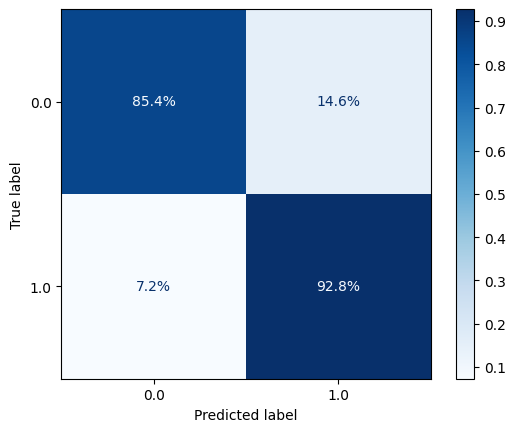

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
0,O13547,GO:0045229,1.0,1.0,0.967236
1,O13547,GO:0071555,1.0,1.0,0.800645
2,O13547,GO:0009987,1.0,1.0,0.984067
3,O13547,GO:0016043,1.0,1.0,0.983643
4,O13547,GO:0071840,1.0,1.0,0.989794
...,...,...,...,...,...
76107,P40035,GO:0010738,0.0,0.0,0.060827
76108,P32806,GO:0047615,0.0,0.0,0.039098
76109,Q08961,GO:0010171,0.0,0.0,0.472616
76110,P47821,GO:0089706,0.0,0.0,0.042688


In [65]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

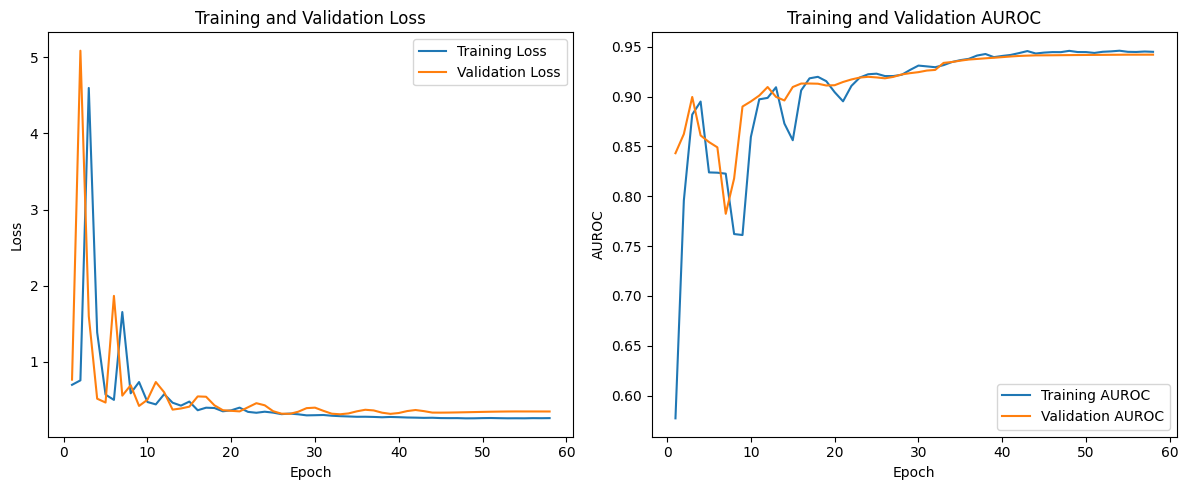

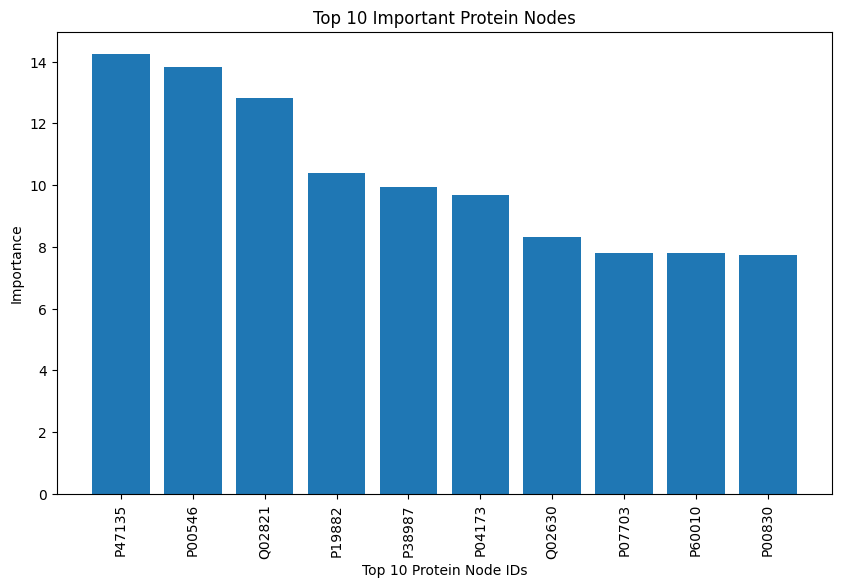

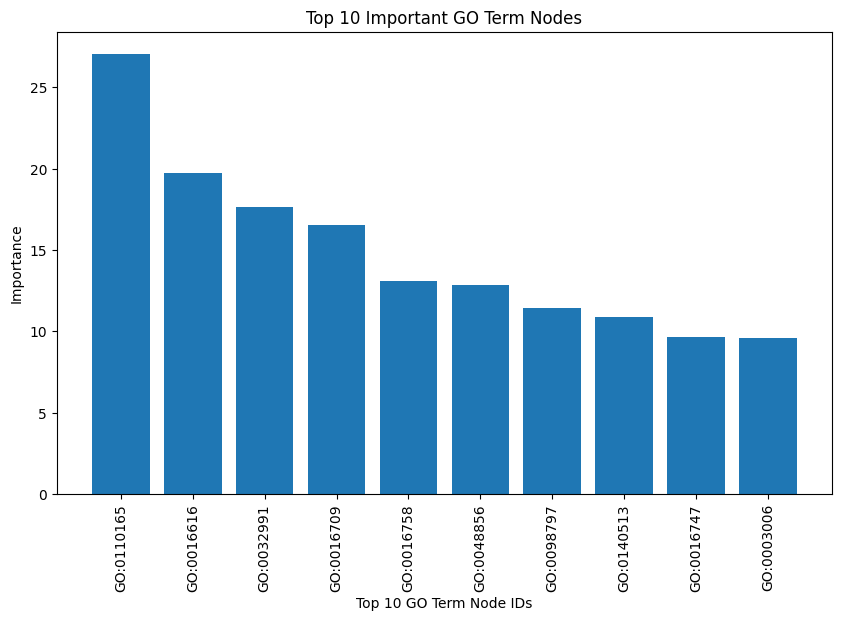

Top Proteins by importance:
['P47135', 'P00546', 'Q02821', 'P19882', 'P38987', 'P04173', 'Q02630', 'P07703', 'P60010', 'P00830']
Top GO terms by importance:
['GO:0110165', 'GO:0016616', 'GO:0032991', 'GO:0016709', 'GO:0016758', 'GO:0048856', 'GO:0098797', 'GO:0140513', 'GO:0016747', 'GO:0003006']


In [66]:
if metrics_dict:
    plot_loss_and_accuracy(metrics_dict, species_folder)

    # Visualizing node importance
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    # Define the mappings (example mappings, replace with actual mappings)
    go_id_mapping = {
        index: go_id for index, go_id in enumerate(hetero_data["go"].id)
    }
    protein_id_mapping = {
        index: protein_id
        for index, protein_id in enumerate(hetero_data["protein"].id)
    }

    # Aggregate attention weights for proteins and GO terms using the correct edge indices
    protein_attention_1 = aggregate_attention_weights(
        attn_weights_protein_1, edge_index_protein_1, hetero_data["protein"].x.size(0)
    )
    protein_attention_2 = aggregate_attention_weights(
        attn_weights_protein_2, edge_index_protein_2, hetero_data["protein"].x.size(0)
    )
    go_attention_1 = aggregate_attention_weights(
        attn_weights_go_1, edge_index_go_1, hetero_data["go"].x.size(0)
    )
    go_attention_2 = aggregate_attention_weights(
        attn_weights_go_2, edge_index_go_2, hetero_data["go"].x.size(0)
    )

    # Visualize protein node importance
    top_protein_ids = visualize_node_importance(protein_attention_1, "Protein", protein_id_mapping)
    # Visualize GO term node importance
    top_go_ids = visualize_node_importance(go_attention_1, "GO Term", go_id_mapping)
else:
    print("Training did not complete correctly, no metrics to plot.")

print("Top Proteins by importance:")
print(top_protein_ids)
print("Top GO terms by importance:")
print(top_go_ids)

In [67]:
# Load best training model

model.load_state_dict(torch.load(species_folder / "models" / "best_model_weights.pt"))
model

HGNNGATNorm(
  (conv1_protein): NormGATConv(1024, 64, heads=8)
  (conv1_go): NormGATConv(384, 64, heads=8)
  (conv2_protein): NormGATConv(512, 64, heads=8)
  (conv2_go): NormGATConv(512, 64, heads=8)
  (protein_to_go): Linear(1024, 1, bias=True)
)

AUROC test: 0.9331281895048632
Balanced accuracy test: 0.8956292864792808
              precision    recall  f1-score   support

           0       0.95      0.88      0.91     50636
           1       0.79      0.91      0.85     25476

    accuracy                           0.89     76112
   macro avg       0.87      0.90      0.88     76112
weighted avg       0.90      0.89      0.89     76112



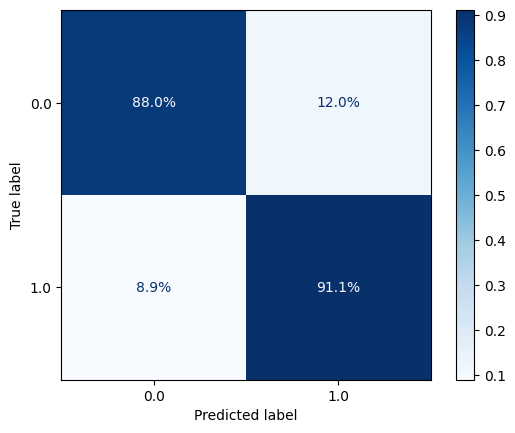

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
0,O13547,GO:0045229,1.0,1.0,0.936998
1,O13547,GO:0071555,1.0,1.0,0.840640
2,O13547,GO:0009987,1.0,1.0,0.953271
3,O13547,GO:0016043,1.0,1.0,0.954869
4,O13547,GO:0071840,1.0,1.0,0.977175
...,...,...,...,...,...
76107,P40035,GO:0010738,0.0,0.0,0.030957
76108,P32806,GO:0047615,0.0,0.0,0.029488
76109,Q08961,GO:0010171,0.0,0.0,0.407238
76110,P47821,GO:0089706,0.0,0.0,0.064514


In [68]:
# Evaluate test

test_results = evaluate_model_performance(
    model, hetero_data, associations_df, go_ids_map, save_path=species_folder
)
test_results

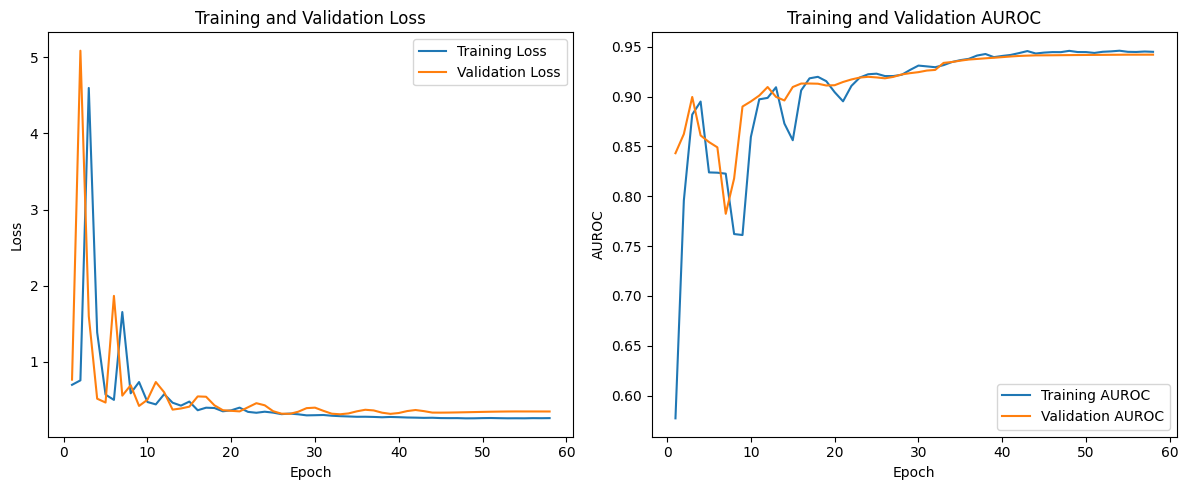

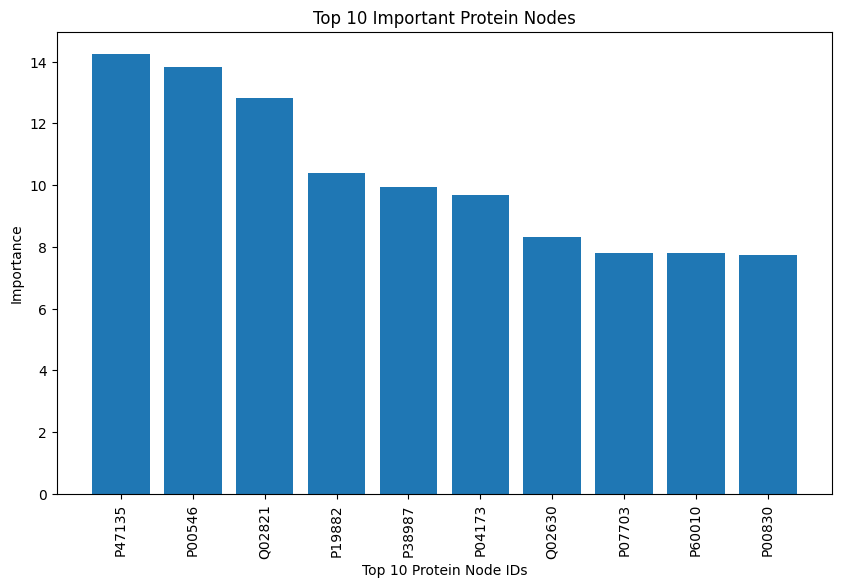

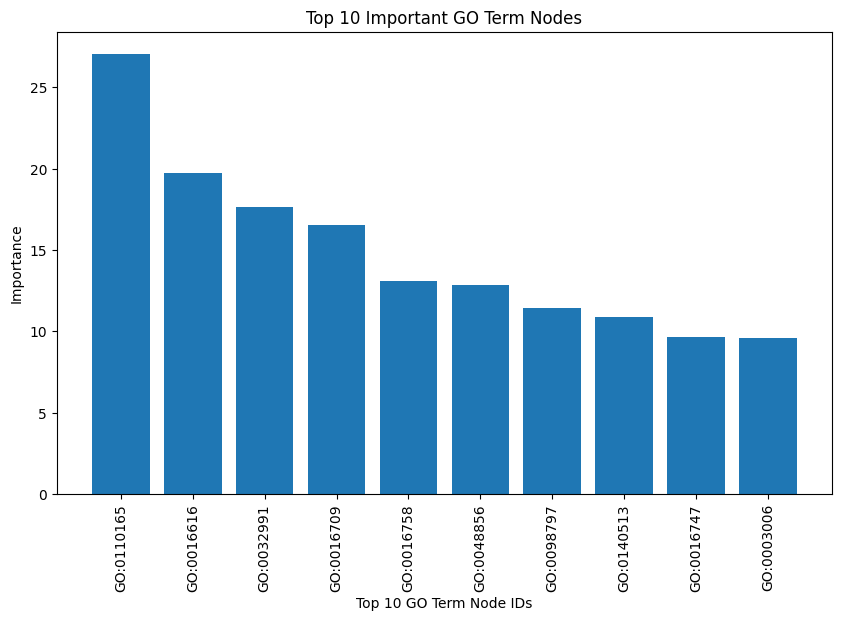

Top Proteins by importance:
['P47135', 'P00546', 'Q02821', 'P19882', 'P38987', 'P04173', 'Q02630', 'P07703', 'P60010', 'P00830']
Top GO terms by importance:
['GO:0110165', 'GO:0016616', 'GO:0032991', 'GO:0016709', 'GO:0016758', 'GO:0048856', 'GO:0098797', 'GO:0140513', 'GO:0016747', 'GO:0003006']


In [69]:
if metrics_dict:
    plot_loss_and_accuracy(metrics_dict, species_folder)

    # Visualizing node importance
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    # Define the mappings (example mappings, replace with actual mappings)
    go_id_mapping = {
        index: go_id for index, go_id in enumerate(hetero_data["go"].id)
    }
    protein_id_mapping = {
        index: protein_id
        for index, protein_id in enumerate(hetero_data["protein"].id)
    }

    # Aggregate attention weights for proteins and GO terms using the correct edge indices
    protein_attention_1 = aggregate_attention_weights(
        attn_weights_protein_1, edge_index_protein_1, hetero_data["protein"].x.size(0)
    )
    protein_attention_2 = aggregate_attention_weights(
        attn_weights_protein_2, edge_index_protein_2, hetero_data["protein"].x.size(0)
    )
    go_attention_1 = aggregate_attention_weights(
        attn_weights_go_1, edge_index_go_1, hetero_data["go"].x.size(0)
    )
    go_attention_2 = aggregate_attention_weights(
        attn_weights_go_2, edge_index_go_2, hetero_data["go"].x.size(0)
    )

    # Visualize protein node importance
    top_protein_ids = visualize_node_importance(protein_attention_1, "Protein", protein_id_mapping)
    # Visualize GO term node importance
    top_go_ids = visualize_node_importance(go_attention_1, "GO Term", go_id_mapping)
else:
    print("Training did not complete correctly, no metrics to plot.")


print("Top Proteins by importance:")
print(top_protein_ids)
print("Top GO terms by importance:")
print(top_go_ids)

In [70]:
go_df[go_df["go_id"].isin(top_go_ids)]

,go_id,name,aspect,def,def_word_count,preprocessed,preproc_word_count
1974,GO:0003006,developmental process involved in reproduction,biological_process,A developmental process in which a progressive...,28,a developmental process in which a progressive...,31
8896,GO:0016616,"oxidoreductase activity, acting on the CH-OH g...",molecular_function,Catalysis of an oxidation-reduction (redox) re...,25,catalysis of an oxidation - reduction ( redox ...,30
8964,GO:0016709,"oxidoreductase activity, acting on paired dono...",molecular_function,Catalysis of an oxidation-reduction (redox) re...,32,catalysis of an oxidation - reduction ( redox ...,37
8994,GO:0016747,"acyltransferase activity, transferring groups ...",molecular_function,"Catalysis of the transfer of an acyl group, ot...",19,"catalysis of the transfer of an acyl group , o...",27
9005,GO:0016758,hexosyltransferase activity,molecular_function,Catalysis of the transfer of a hexosyl group f...,15,catalysis of the transfer of a hexosyl group f...,20
14003,GO:0032991,protein-containing complex,cellular_component,A stable assembly of two or more macromolecule...,31,a stable assembly of two or more macromolecule...,35
22909,GO:0048856,anatomical structure development,biological_process,The biological process whose specific outcome ...,76,the biological process whose specific outcome ...,82
31698,GO:0098797,plasma membrane protein complex,cellular_component,Any protein complex that is part of the plasma...,10,any protein complex that be part of the plasma...,11
33576,GO:0110165,cellular anatomical entity,cellular_component,A part of a cellular organism that is either a...,49,a part of a cellular organism that be either a...,52
34223,GO:0140513,nuclear protein-containing complex,cellular_component,A stable assembly of two or more macromolecule...,34,a stable assembly of two or more macromolecule...,38


In [71]:
ppi_df[(ppi_df["uniprot_id_A"].isin(top_protein_ids[:1])) | ppi_df["uniprot_id_B"].isin(top_protein_ids[:1])]

,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
458,P23285,P47135,physical interaction,two hybrid,,4932,4932
530,P47135,P36131,physical interaction,two hybrid,,4932,4932
1072,P40515,P47135,physical interaction,two hybrid,,4932,4932
1096,P18634,P47135,physical interaction,two hybrid,,4932,4932
4795,P30624,P47135,physical association,two hybrid pooling approach,,4932,4932
...,...,...,...,...,...,...,...
5202,P47135,Q05933,physical association,two hybrid pooling approach,,4932,4932
14073,P00546,P47135,physical interaction,protein kinase assay,,4932,4932
16084,P47135,P53906,physical association,two hybrid pooling approach,,4932,4932
16085,P47135,Q3E7X9,physical association,two hybrid pooling approach,,4932,4932


In [72]:
test_results[test_results["Ground Truth Label"] == test_results["Predicted Label"]]

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
0,O13547,GO:0045229,1.0,1.0,0.936998
1,O13547,GO:0071555,1.0,1.0,0.840640
2,O13547,GO:0009987,1.0,1.0,0.953271
3,O13547,GO:0016043,1.0,1.0,0.954869
4,O13547,GO:0071840,1.0,1.0,0.977175
...,...,...,...,...,...
76107,P40035,GO:0010738,0.0,0.0,0.030957
76108,P32806,GO:0047615,0.0,0.0,0.029488
76109,Q08961,GO:0010171,0.0,0.0,0.407238
76110,P47821,GO:0089706,0.0,0.0,0.064514


In [74]:
test_results[test_results["Ground Truth Label"] != test_results["Predicted Label"]]

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
30,P00128,GO:0033108,1.0,0.0,0.032925
37,P00128,GO:0017062,1.0,0.0,0.032925
40,P00128,GO:0034551,1.0,0.0,0.029948
54,P00128,GO:0006122,1.0,0.0,0.029948
60,P00812,GO:0009065,1.0,0.0,0.453479
...,...,...,...,...,...
76073,Q04991,GO:0022607,0.0,1.0,0.955141
76082,P12684,GO:0019238,0.0,1.0,0.654834
76096,P38930,GO:0035780,0.0,1.0,0.500507
76102,Q07938,GO:0048316,0.0,1.0,0.531082


In [73]:
test_results[
    (test_results["Ground Truth Label"] == 0.0)
    & (test_results["Predicted Label"] == 1.0)
].sort_values(by="Probability", ascending=False).head(30)

,Protein ID,GO ID,Ground Truth Label,Predicted Label,Probability
71889,P38274,GO:0019866,0.0,1.0,0.998910
43730,P25348,GO:0009503,0.0,1.0,0.997702
72919,P19158,GO:0044423,0.0,1.0,0.997454
30407,P36019,GO:0099243,0.0,1.0,0.997383
66924,P06197,GO:0034399,0.0,1.0,0.997339
45893,P06197,GO:0007316,0.0,1.0,0.997286
54507,P22543,GO:0098645,0.0,1.0,0.997123
33573,P25348,GO:0005819,0.0,1.0,0.996940
67960,P06197,GO:0000028,0.0,1.0,0.996396
63945,Q03029,GO:0005838,0.0,1.0,0.996178


In [77]:
print(go_df[go_df["go_id"] == "GO:0034399"].to_markdown())

|       | go_id      | name              | aspect             | def                                                                      |   def_word_count | preprocessed                                                              |   preproc_word_count |
|------:|:-----------|:------------------|:-------------------|:-------------------------------------------------------------------------|-----------------:|:--------------------------------------------------------------------------|---------------------:|
| 15286 | GO:0034399 | nuclear periphery | cellular_component | The portion of the nuclear lumen proximal to the inner nuclear membrane. |               12 | the portion of the nuclear luman proximal to the inner nuclear membrane . |                   13 |


In [ ]:
# Evaluate one protein

protein = test_results["Protein ID"][100]

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label", "Predicted Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Ground Truth Label"])
    .sort_index()
)

print(
    test_results[test_results["Protein ID"] == protein]
    .value_counts(subset=["Predicted Label"])
    .sort_index()
)